In [4]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration and benchmarking of robust gateset

First, we activate the IBM service we are going to be using.

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

And we get backend information.

In [3]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_brisbane")
dt = backend.configuration().dt * ns

# original duration was 120 dt, we take multiples of this
desired_duration = 240  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 240)

Then we load our robust gateset.

In [11]:
# pico_a = ps.from_csv(
#     "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
# )
pico_a = ps.from_csv("../pico-pulses/saved-pulses-2024-09-02/gateset.csv")
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2", "i2"], pico_a)}

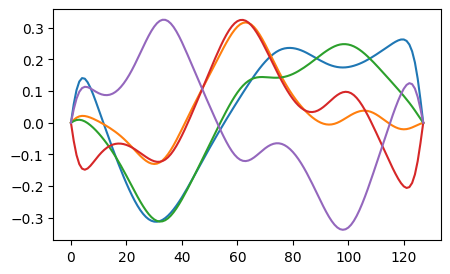

In [12]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

And we define a Guassian gateset to which we are going to compare.

In [13]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
}

The maximum aplitude allowed by qiskit pulse is the `amp` factor times the amplitude of the signal we are sending.

In [14]:
signal = pico_gates["x1"]
x1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx1"]
sx1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x1_max, sx1_max)
print(1 / x1_max, 1 / sx1_max)

0.16666839392947655 0.16640351063566824
5.99993781918326 6.009488599008272


In [15]:
signal = pico_gates["x2"]
x2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx2"]
sx2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x2_max, sx2_max)
print(1 / x2_max, 1 / sx2_max)

0.16905995559868833 0.17333103644156922
5.9150612956138655 5.769307220043683


So we can bump up the `drive_amps` closer to -3 and 3.

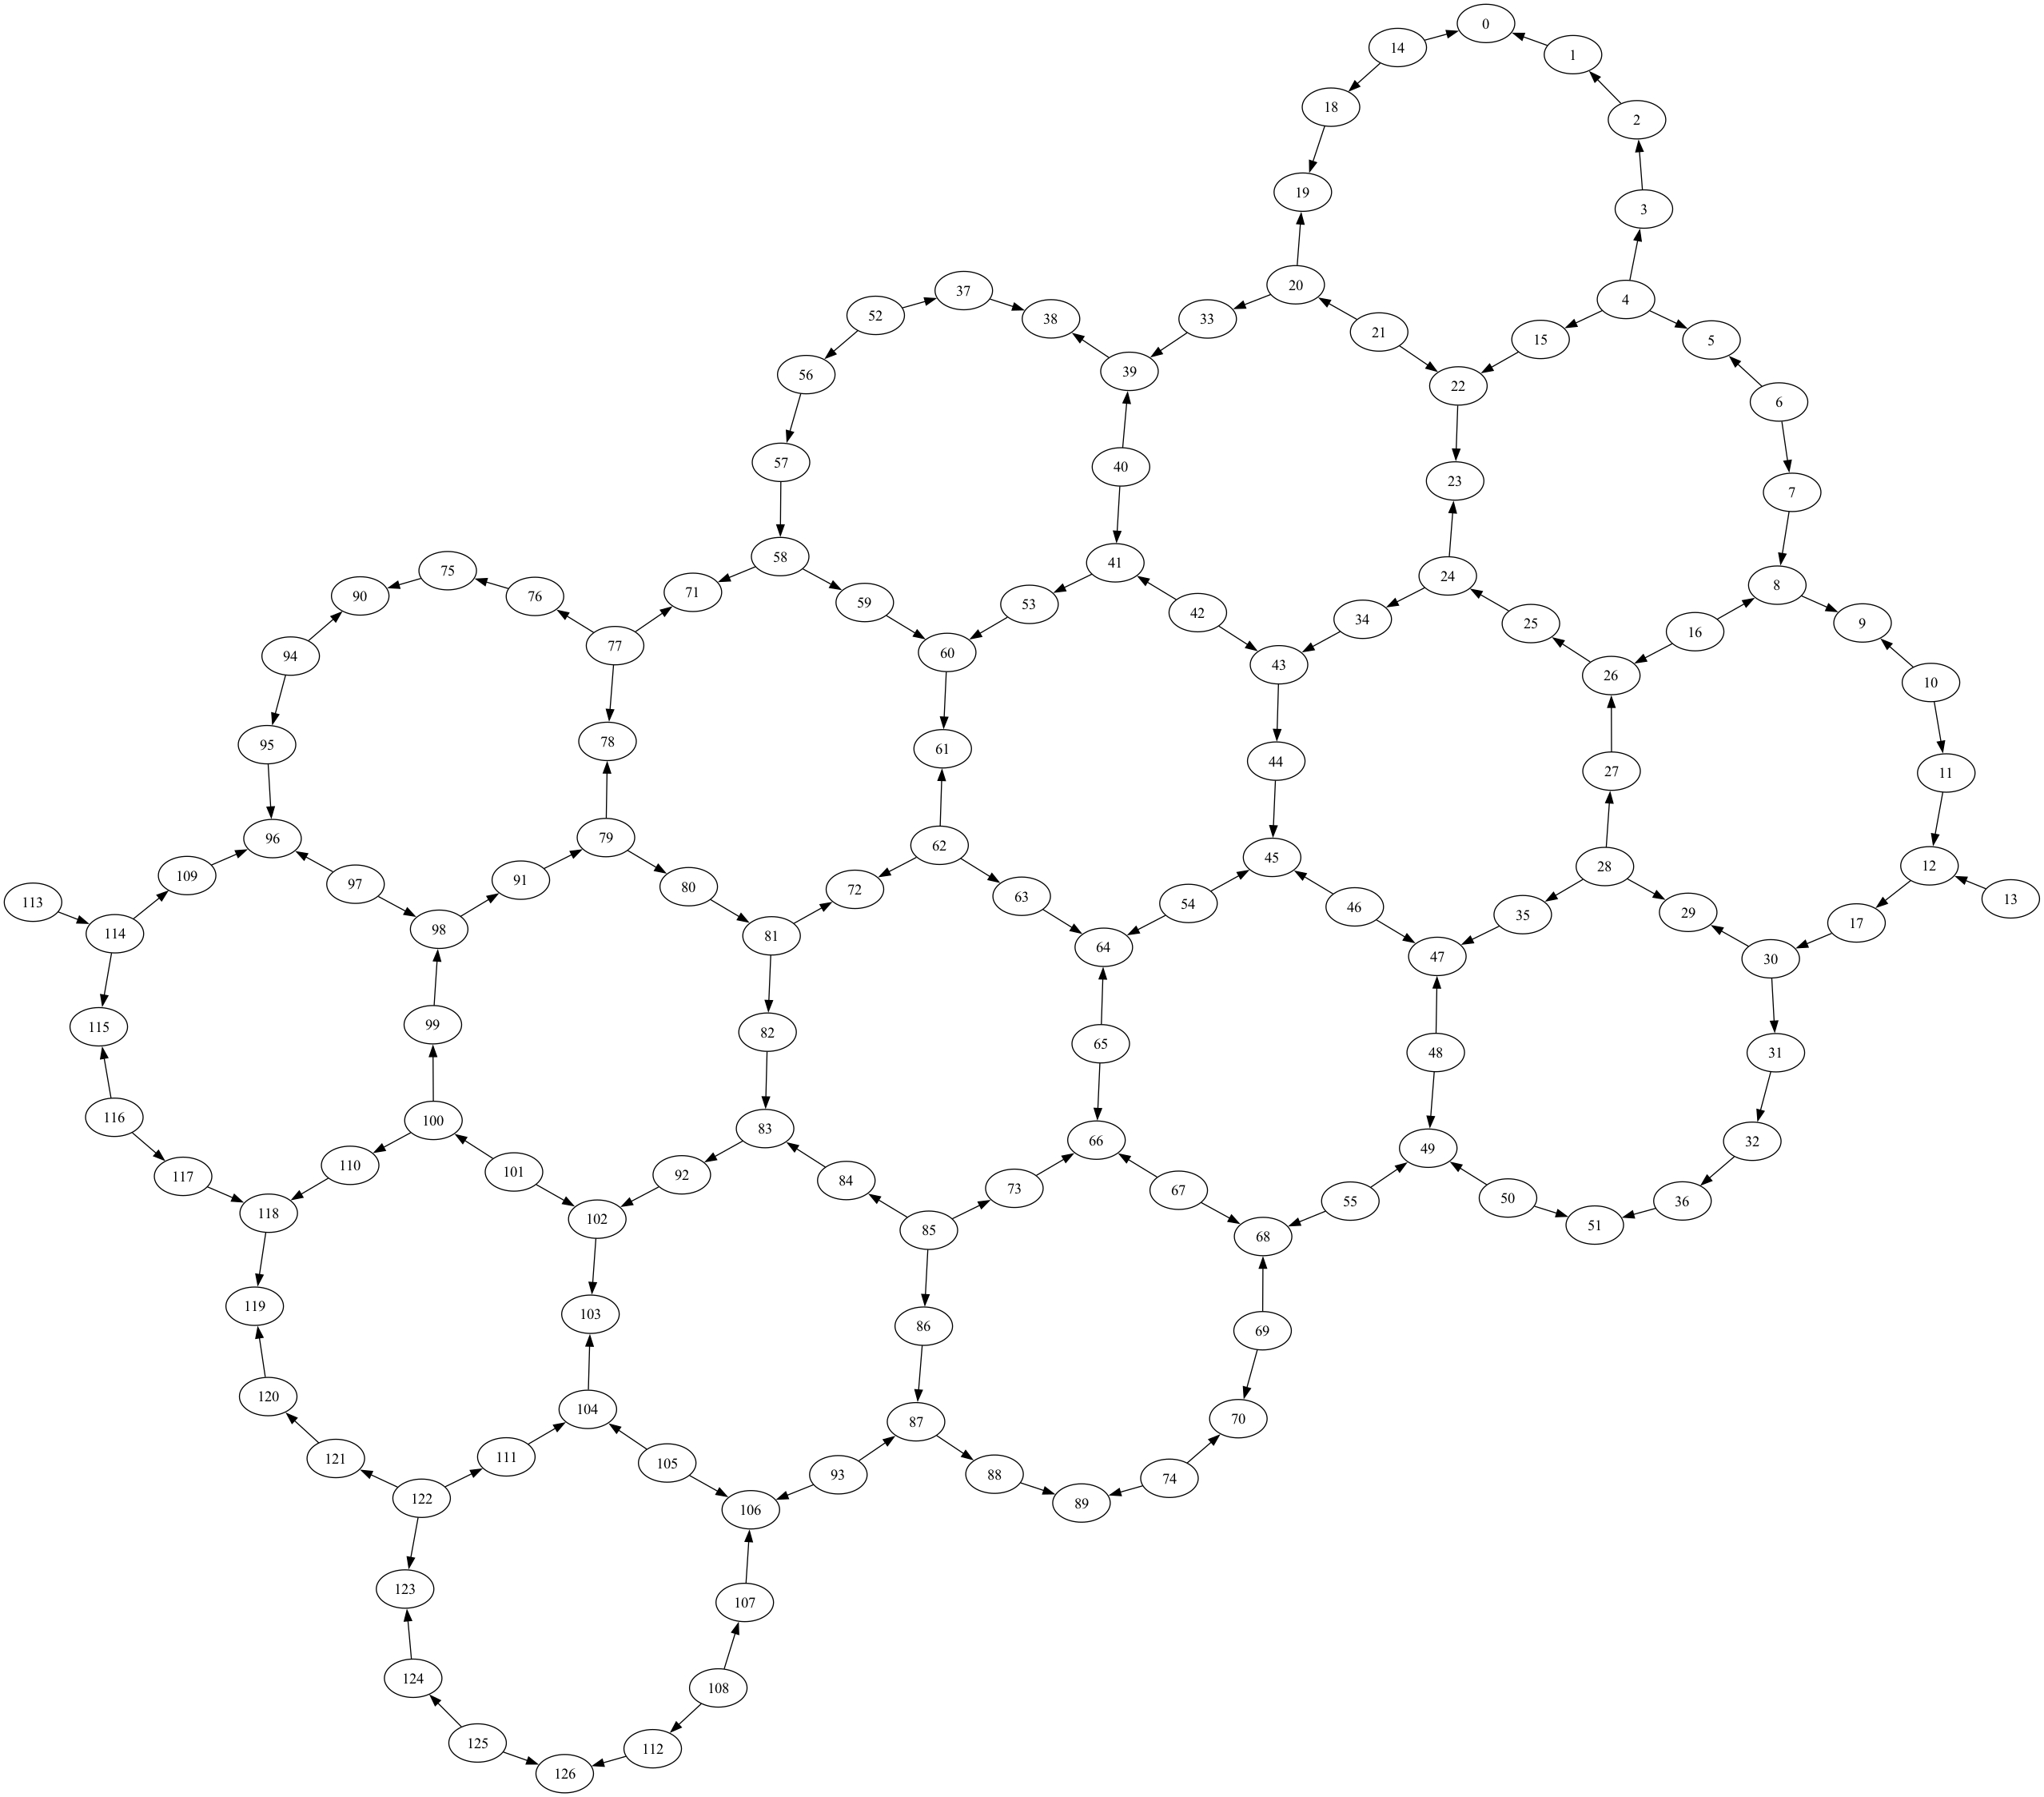

In [135]:
backend.coupling_map.draw()

## Rough amplitude calibration

We choose two qubits with good T1/T2 times and a range of amplitudes to calibrate the gates.

In [136]:
qubit0, qubit1 = 18, 14
qubit2, qubit3 = 0, 1
# qubit4, qubit5 = 8, 9
# qubit6, qubit7 = 10, 11

x_drive_amps = np.linspace(-2.5, 2.5, 50)
sx_drive_amps = np.linspace(-4, 4, 50)

And we create schedules with our robust gates using this range of amplitudes.

In [137]:
def get_schedules(signal, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"rabi_sched", backend=backend) as sched:
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, "custom", amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [138]:
robust_x1_schedules = get_schedules(pico_gates["x1"], qubit0, x_drive_amps)

We do the same for the Gaussian pulses.

In [139]:
gaussian_x1_schedules = get_schedules(default_gates["x1"].samples, qubit0, x_drive_amps)

We can use the schedules to create circuits that we can run to IBM.

In [56]:
num_qubits = backend.num_qubits
num_qubits

127

In [140]:
def get_circuits_from_scheds(schedules, num_qubits: int, qubit: int):
    circuits = []
    for i, schedule in enumerate(schedules):
        gate = qk.circuit.Gate(f"x_rabi", 1, [])
        cr = qk.ClassicalRegister(1, name="c")
        qr = qk.QuantumRegister(num_qubits, name="q")
        qc = qk.QuantumCircuit(qr, cr, name=f"schedule")
        qc.append(gate, [qubit])
        qc.measure(qubit, cr[0])
        qc.add_calibration(gate, (qubit,), schedule)
        circuits.append(qc)
    return circuits

In [141]:
robust_x1_circuits = get_circuits_from_scheds(robust_x1_schedules, num_qubits, qubit0)
robust_x1_circuits[0].draw(idle_wires=False)

┌────────┐┌─┐
q_18: ┤ x_rabi ├┤M├
      └────────┘└╥┘
 c: 1/═══════════╩═
                 0

We can parallelize our calibration by running circuits that act on different qubits at the same time. So, we can calibrate both x gates in parallel, and both sx gates in parallel. We can also do more qubit pairs.

In [142]:
def construct_parallel_circuits(qubits: list[int], signals, drive_amps_list: list[list[float]], num_qubits: int):
    assert len(qubits) == len(signals)

    qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(len(drive_amps_list[0]))]
    crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(len(drive_amps_list[0]))]
    qcs = [qk.QuantumCircuit(qrs[i], crs[i]) for i in range(len(drive_amps_list[0]))]

    for i, (qubit, signal) in enumerate(zip(qubits, signals)):
        schedules = get_schedules(signal, qubit, drive_amps_list[i])
        circuits = get_circuits_from_scheds(schedules, num_qubits, qubit)
        
        for j, (qc, circuit) in enumerate(zip(qcs, circuits)):
            qc.append(circuit, qargs=qrs[j], cargs=(crs[j][i],))

            # have to add calibrations to new circuit
            gate = qk.circuit.Gate("x_rabi", 1, [])
            qc.add_calibration(gate, (qubit,), schedules[j])

    return [qc.decompose() for qc in qcs]

In [143]:
# qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5, qubit6, qubit7]
# qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5]
qubits = [qubit0, qubit1, qubit2, qubit3]
x_signals = [pico_gates["x1"], pico_gates["x2"]] * 2
sx_signals = [pico_gates["sx1"], pico_gates["sx2"]] * 2

x_parallel_circuits = construct_parallel_circuits(qubits, x_signals, [x_drive_amps] * 4, num_qubits)
sx_parallel_circuits = construct_parallel_circuits(qubits, sx_signals, [sx_drive_amps] * 4, num_qubits)

In [144]:
x_signals_gaussian = [default_gates["x1"].samples, default_gates["x2"].samples] * 2
sx_signals_gaussian = [default_gates["sx1"].samples, default_gates["sx2"].samples] * 2

x_parallel_circuits_gaussian = construct_parallel_circuits(qubits, x_signals_gaussian, [x_drive_amps] * 4, num_qubits)
sx_parallel_circuits_gaussian = construct_parallel_circuits(qubits, sx_signals_gaussian, [sx_drive_amps] * 4, num_qubits)

In [145]:
x_parallel_circuits[3].draw(idle_wires=False)

┌────────┐      ┌─┐   
 q_0: ┤ x_rabi ├──────┤M├───
      ├────────┤      └╥┘┌─┐
 q_1: ┤ x_rabi ├───────╫─┤M├
      ├────────┤   ┌─┐ ║ └╥┘
q_14: ┤ x_rabi ├───┤M├─╫──╫─
      ├────────┤┌─┐└╥┘ ║  ║ 
q_18: ┤ x_rabi ├┤M├─╫──╫──╫─
      └────────┘└╥┘ ║  ║  ║ 
 c: 4/═══════════╩══╩══╩══╩═
                 0  1  2  3

So, as you can see above, we parallelize the rough calibration by running circuits of the form above (we omit idle wires in the drawing to save space).

We can now run the calibration jobs. But first, we have to open a runtime session and save its id.

In [146]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: cvyamjtsmnpg0082py3g


In [147]:
sampler = Sampler(backend=backend, session=session)
sampler.options.experimental = {"execution": {"fast_parametric_update": False}} # make sure pulse instructions are sent correctly

In [148]:
num_shots_per_point = 1024

In [149]:
x_parallel_jobs = sampler.run(x_parallel_circuits, shots=num_shots_per_point)
sx_parallel_jobs = sampler.run(sx_parallel_circuits, shots=num_shots_per_point)

x_parallel_jobs_gaussian = sampler.run(x_parallel_circuits_gaussian, shots=num_shots_per_point)
sx_parallel_jobs_gaussian = sampler.run(sx_parallel_circuits_gaussian, shots=num_shots_per_point)

In [150]:
x_parallel_jobs.job_id(), sx_parallel_jobs.job_id()

('cvyamkt5e7xg008tzp6g', 'cvyamma5e7xg008tzp70')

In [151]:
x_parallel_jobs_gaussian.job_id(), sx_parallel_jobs_gaussian.job_id()

('cvyammjfd8tg008xe6p0', 'cvyamn2smnpg0082py4g')

In [164]:
x_parallel_jobs.status(), sx_parallel_jobs.status()

(<JobStatus.QUEUED: 'job is queued'>, <JobStatus.QUEUED: 'job is queued'>)

In [165]:
x_parallel_jobs_gaussian.status(), sx_parallel_jobs_gaussian.status()

(<JobStatus.QUEUED: 'job is queued'>, <JobStatus.QUEUED: 'job is queued'>)

In [154]:
x_parallel_jobs = service.job("cvyamkt5e7xg008tzp6g")
sx_parallel_jobs = service.job("cvyamma5e7xg008tzp70")

In [155]:
x_parallel_jobs_gaussian = service.job("cvyammjfd8tg008xe6p0")
sx_parallel_jobs_gaussian = service.job("cvyamn2smnpg0082py4g")

We define the functions that will help us analyze the calibration data.

In [82]:
def get_qubit_one_counts(counts, qubit, num_qubits):
    total = 0
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] == "1": # because of little-endian
            total += val
    return total

In [83]:
def get_rabi_values(job, shots, qubits):
    rabi_values = [[] for _ in range(len(qubits))] # each list element is the data for a single qubit
    result = job.result()
    for i in range(len(result)):
        counts = result[i].data.c.get_counts()
        for j in range(len(qubits)):
            rabi_values[j].append(get_qubit_one_counts(counts, j, len(qubits)) / shots)
    return rabi_values

In [84]:
x_rabi_values = get_rabi_values(x_parallel_jobs, num_shots_per_point, qubits)
sx_rabi_values = get_rabi_values(sx_parallel_jobs, num_shots_per_point, qubits)

In [85]:
x_rabi_values_gaussian = get_rabi_values(x_parallel_jobs_gaussian, num_shots_per_point, qubits)
sx_rabi_values_gaussian = get_rabi_values(sx_parallel_jobs_gaussian, num_shots_per_point, qubits)

In [86]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    return fitparams, y_fit, conv

def baseline_remove(values):
    return np.array(values) - np.mean(values)

In [87]:
def get_drive_period(
    rabi_values: list[float], 
    drive_amps: list[float], 
    target_angle: float,
    gate_name: str = "",
    plot: bool = False, 
    qubit: int = 0,
    amplitude_max: float = 1,
    normal_params: bool = True,
):
    """factor is 2 for x gates and 4 for sx gates"""
    rabi_values = np.real(rabi_values)
    
    starting_params = [0.2] if normal_params else [0.4]
    fit_params, y_fit, _ = fit_function(
        drive_amps,
        rabi_values,
        lambda x, f: (
            0.5 * np.cos(2 * np.pi * x * f + np.pi) + 0.5
        ),
        starting_params,
    )

    freq = fit_params[0]  # get period of rabi oscillation
    
    if plot:
        plot_amps = amplitude_max * np.array(drive_amps)
        plt.scatter(plot_amps, rabi_values, marker="x", color="black")
        plt.plot(plot_amps, y_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1 (baseline removed)")
        plt.title(f"{gate_name} calibration on qubit {qubit}")
        plt.show()

    return target_angle / (2 * np.pi * freq)

And we get the estimated amplitudes.

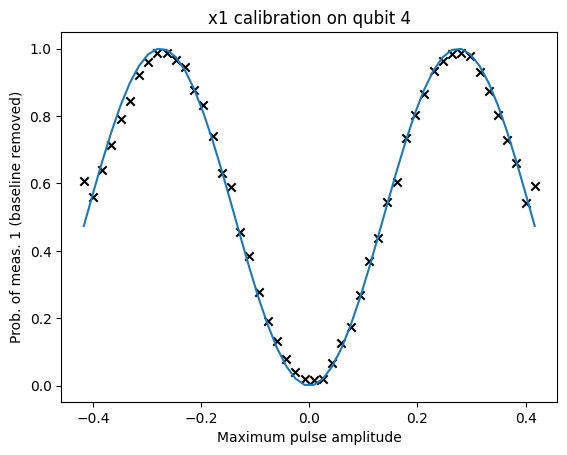

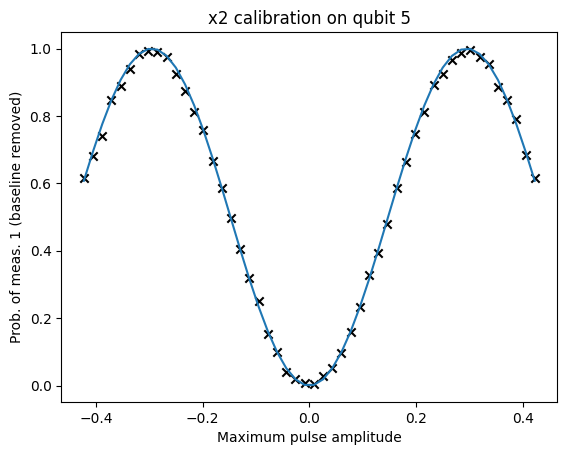

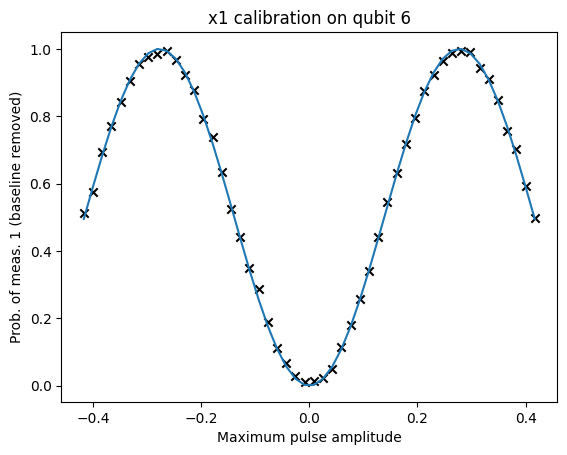

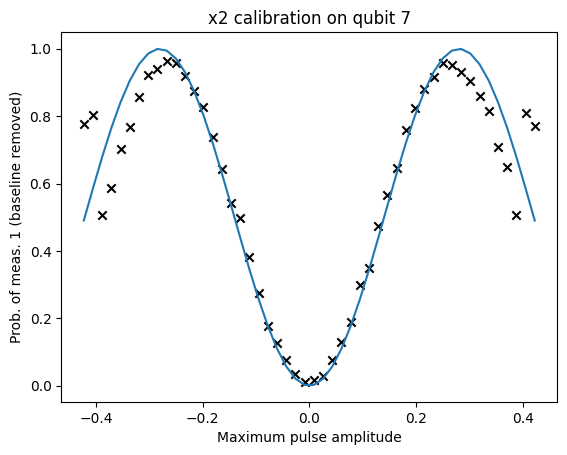

In [89]:
x_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values)):
    x_rough_amps.append(get_drive_period(
        rabi,
        x_drive_amps,
        target_angle=np.pi,
        gate_name=f"x{i % 2 + 1}",
        plot=True, 
        qubit=qubit, 
        amplitude_max= x1_max if i % 2 == 0 else x2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))

In [90]:
x_rough_amps

[1.6483381380808744,
 1.7469955940961204,
 1.6631867541104877,
 1.6598399452528336]

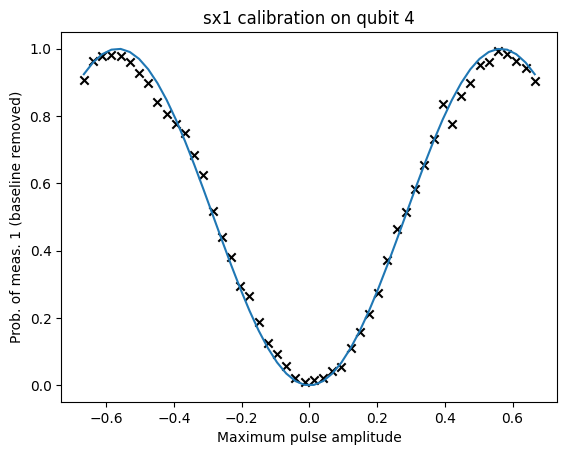

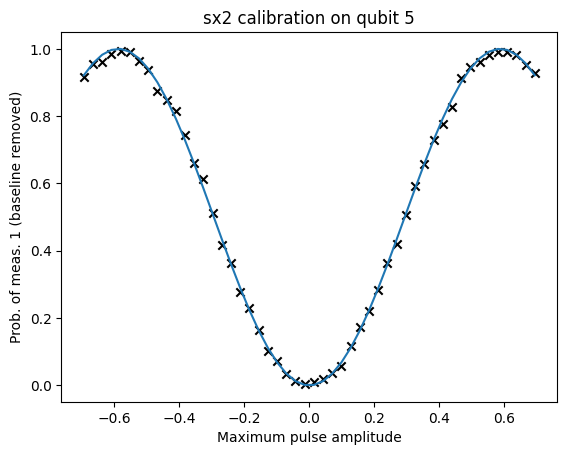

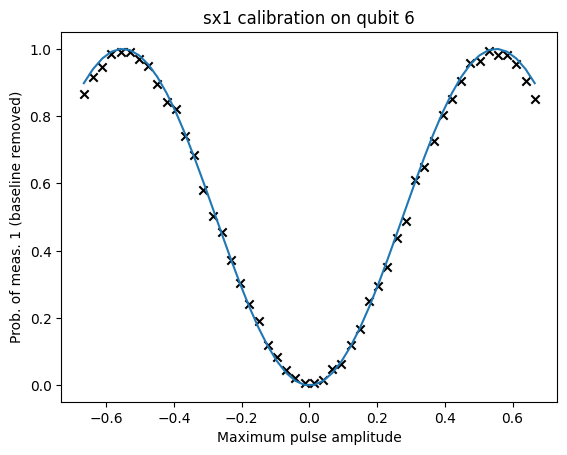

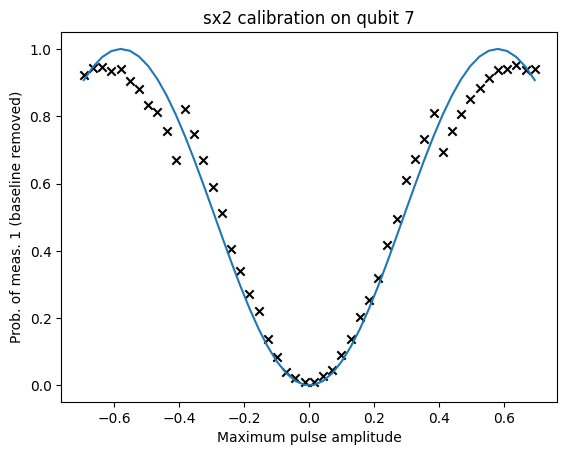

In [91]:
sx_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, sx_rabi_values)):
    sx_rough_amps.append(get_drive_period(
        rabi, 
        sx_drive_amps, 
        target_angle=np.pi / 2,
        gate_name=f"sx{i % 2 + 1}", 
        plot=True, 
        qubit=qubit,
        amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))


In [92]:
sx_rough_amps

[1.6985311990314316,
 1.6934473262054486,
 1.6570822527152356,
 1.6708974348910957]

In [93]:
x_rough_amps_gaussian = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values_gaussian)):
    x_rough_amps_gaussian.append(get_drive_period(
        rabi, 
        x_drive_amps, 
        target_angle=np.pi,
        gate_name=f"x{i % 2 + 1}", 
        plot=False, 
        qubit=qubit,
        # amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))
x_rough_amps_gaussian

[3.1959804631639415, 3.4730388885984445, 3.275817044264644, 3.119149637944339]

In [94]:
sx_rough_amps_gaussian = []
for i, (qubit, rabi) in enumerate(zip(qubits, sx_rabi_values_gaussian)):
    sx_rough_amps_gaussian.append(get_drive_period(
        rabi, 
        sx_drive_amps, 
        target_angle=np.pi / 2,
        gate_name=f"sx{i % 2 + 1}", 
        plot=False, 
        qubit=qubit,
        # amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))
sx_rough_amps_gaussian

[3.1947895999828284, 3.448875621066815, 3.272341679831199, 3.10329713270099]

In [95]:
for i, (qubit, amp) in enumerate(zip(qubits, x_rough_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amp: {amp}")

Qubit 4 x1 gate amp: 1.6483381380808744
Qubit 5 x2 gate amp: 1.7469955940961204
Qubit 6 x1 gate amp: 1.6631867541104877
Qubit 7 x2 gate amp: 1.6598399452528336


In [96]:
for i, (qubit, amp) in enumerate(zip(qubits, sx_rough_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amp: {amp}")

Qubit 4 sx1 gate amp: 1.6985311990314316
Qubit 5 sx2 gate amp: 1.6934473262054486
Qubit 6 sx1 gate amp: 1.6570822527152356
Qubit 7 sx2 gate amp: 1.6708974348910957


In [97]:
for i, (x_period, sx_period) in enumerate(zip(x_rough_amps, sx_rough_amps)):
    print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_period / x_period)

Ratio of sx1 to x1 on qubit 4: 1.0304507065576944
Ratio of sx2 to x2 on qubit 5: 0.9693483669497305
Ratio of sx1 to x1 on qubit 6: 0.9963296356346243
Ratio of sx2 to x2 on qubit 7: 1.0066617806553497


## Fine amplitude calibration

We can then use the amplitudes from the rough calibration and further calibrate them using the fine calibration protocol.

In [98]:
def build_schedule(signal, qubit: int, amp: float):
    with qk.pulse.build(backend=backend) as sched:
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp
        )
        qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
    return sched

In [99]:
def get_fine_experiment(sched, qubit: int, gate: str, backend, x_gate: bool = True):
    inst_map = qk.pulse.InstructionScheduleMap()
    inst_map.add(gate, (qubit,), sched)
    if x_gate:
        exp = qk_e.library.FineXAmplitude((qubit,), backend)
    else:
        exp = qk_e.library.FineSXAmplitude((qubit,), backend)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

We know construct the fine amplitude experiments.

In [100]:
fine_x_experiments = []
fine_sx_experiments = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals)):
    sched = build_schedule(signal, qubit, x_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "x", backend, x_gate=True)
    fine_x_experiments.append(exp)

for i, (qubit, signal) in enumerate(zip(qubits, sx_signals)):
    sched = build_schedule(signal, qubit, sx_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "sx", backend, x_gate=False)
    fine_sx_experiments.append(exp)

In [101]:
fine_x_experiments_gaussian = []
fine_sx_experiments_gaussian = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals_gaussian)):
    sched = build_schedule(signal, qubit, x_rough_amps_gaussian[i])
    exp = get_fine_experiment(sched, qubit, "x", backend, x_gate=True)
    fine_x_experiments_gaussian.append(exp)

for i, (qubit, signal) in enumerate(zip(qubits, sx_signals_gaussian)):
    sched = build_schedule(signal, qubit, sx_rough_amps_gaussian[i])
    exp = get_fine_experiment(sched, qubit, "sx", backend, x_gate=False)
    fine_sx_experiments_gaussian.append(exp)

And parallelize them like we did with the rough calibration circuits.

In [102]:
x_num_circuits = len(fine_x_experiments[0].circuits())
x_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits = [qk.QuantumCircuit(x_qrs[i], x_crs[i]) for i in range(x_num_circuits)]

sx_num_circuits = len(fine_sx_experiments[0].circuits())
sx_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
sx_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
fine_sx_circuits = [qk.QuantumCircuit(sx_qrs[i], sx_crs[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits = fine_x_experiments[i].circuits()
    sx_circuits = fine_sx_experiments[i].circuits()

    x_schedule = build_schedule(x_signals[i], qubit, x_rough_amps[i])
    sx_schedule = build_schedule(sx_signals[i], qubit, sx_rough_amps[i])

    for j in range(x_num_circuits):
        fine_x_circuits[j].append(x_circuits[j], qargs=(x_qrs[j][qubit],), cargs=(x_crs[j][i],))
        gate = qk.circuit.library.XGate()
        fine_x_circuits[j].add_calibration(gate, (qubit,), x_schedule)
        
    for j in range(sx_num_circuits):
        fine_sx_circuits[j].append(sx_circuits[j], qargs=(sx_qrs[j][qubit],), cargs=(sx_crs[j][i],))
        gate = qk.circuit.library.SXGate()
        fine_sx_circuits[j].add_calibration(gate, (qubit,), sx_schedule)

fine_x_circuits = [circuit.decompose() for circuit in fine_x_circuits]
fine_sx_circuits = [circuit.decompose() for circuit in fine_sx_circuits]

In [103]:
fine_x_circuits[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐┌─┐         
q_4: ┤ √X ├┤ X ├┤ X ├┤M├─────────
     ├────┤├───┤├───┤└╥┘┌─┐      
q_5: ┤ √X ├┤ X ├┤ X ├─╫─┤M├──────
     ├────┤├───┤├───┤ ║ └╥┘┌─┐   
q_6: ┤ √X ├┤ X ├┤ X ├─╫──╫─┤M├───
     ├────┤├───┤├───┤ ║  ║ └╥┘┌─┐
q_7: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫─┤M├
     └────┘└───┘└───┘ ║  ║  ║ └╥┘
c: 4/═════════════════╩══╩══╩══╩═
                      0  1  2  3

In [104]:
fine_x_circuits[3].calibrations["x"][((qubit0,), ())] # we can check calibrations were added 

ScheduleBlock(Play(Waveform(array([ 0.01336182+0.j,  0.0414683 +0.j,  0.06513024+0.j,  0.08506974+0.j,
        0.10094129+0.j,  0.11199794+0.j,  0.11958353+0.j,  0.1229861 +0.j,
        0.12365549+0.j,  0.1212638 +0.j,  0.11685487+0.j,  0.11046052+0.j,
        0.10266324+0.j,  0.09372125+0.j,  0.08386115+0.j,  0.07344129+0.j,
        0.06240573+0.j,  0.05120529+0.j,  0.03970222+0.j,  0.02815015+0.j,
        0.01650236+0.j,  0.00486432+0.j, -0.00675922+0.j, -0.01833919+0.j,
       -0.02984717+0.j, -0.04129049+0.j, -0.05262763+0.j, -0.06388419+0.j,
       -0.07500811+0.j, -0.08603486+0.j, -0.09691064+0.j, -0.10763898+0.j,
       -0.11822276+0.j, -0.12862078+0.j, -0.13885268+0.j, -0.14885823+0.j,
       -0.15867062+0.j, -0.16821055+0.j, -0.17752904+0.j, -0.18653177+0.j,
       -0.1952966 +0.j, -0.20369248+0.j, -0.21181633+0.j, -0.21950027+0.j,
       -0.2268612 +0.j, -0.23373031+0.j, -0.24011677+0.j, -0.2460591 +0.j,
       -0.25143086+0.j, -0.25633533+0.j, -0.26061605+0.j, -0.26440715+0.

In [105]:
x_num_circuits = len(fine_x_experiments_gaussian[0].circuits())
x_qrs_gaussian = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs_gaussian = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits_gaussian = [qk.QuantumCircuit(x_qrs_gaussian[i], x_crs_gaussian[i]) for i in range(x_num_circuits)]

sx_num_circuits = len(fine_sx_experiments_gaussian[0].circuits())
sx_qrs_gaussian = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
sx_crs_gaussian = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
fine_sx_circuits_gaussian = [qk.QuantumCircuit(sx_qrs_gaussian[i], sx_crs_gaussian[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits_gaussian = fine_x_experiments_gaussian[i].circuits()
    sx_circuits_gaussian = fine_sx_experiments_gaussian[i].circuits()

    x_schedule_gaussian = build_schedule(x_signals_gaussian[i], qubit, x_rough_amps_gaussian[i])
    sx_schedule_gaussian = build_schedule(sx_signals_gaussian[i], qubit, sx_rough_amps_gaussian[i])

    for j in range(x_num_circuits):
        fine_x_circuits_gaussian[j].append(x_circuits_gaussian[j], qargs=(x_qrs_gaussian[j][qubit],), cargs=(x_crs_gaussian[j][i],))
        gate = qk.circuit.library.XGate()
        fine_x_circuits_gaussian[j].add_calibration(gate, (qubit,), x_schedule_gaussian)
        
    for j in range(sx_num_circuits):
        fine_sx_circuits_gaussian[j].append(sx_circuits_gaussian[j], qargs=(sx_qrs_gaussian[j][qubit],), cargs=(sx_crs_gaussian[j][i],))
        gate = qk.circuit.library.SXGate()
        fine_sx_circuits_gaussian[j].add_calibration(gate, (qubit,), sx_schedule_gaussian)

fine_x_circuits_gaussian = [circuit.decompose() for circuit in fine_x_circuits_gaussian]
fine_sx_circuits_gaussian = [circuit.decompose() for circuit in fine_sx_circuits_gaussian]

In [106]:
fine_x_circuits_gaussian[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐┌─┐         
q_4: ┤ √X ├┤ X ├┤ X ├┤M├─────────
     ├────┤├───┤├───┤└╥┘┌─┐      
q_5: ┤ √X ├┤ X ├┤ X ├─╫─┤M├──────
     ├────┤├───┤├───┤ ║ └╥┘┌─┐   
q_6: ┤ √X ├┤ X ├┤ X ├─╫──╫─┤M├───
     ├────┤├───┤├───┤ ║  ║ └╥┘┌─┐
q_7: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫─┤M├
     └────┘└───┘└───┘ ║  ║  ║ └╥┘
c: 4/═════════════════╩══╩══╩══╩═
                      0  1  2  3

And we submit this parallel jobs.

In [107]:
num_shots = 2048

In [108]:
x_fine_jobs = sampler.run(fine_x_circuits, shots=num_shots)
sx_fine_jobs = sampler.run(fine_sx_circuits, shots=num_shots)

x_fine_jobs_gaussian = sampler.run(fine_x_circuits_gaussian, shots=num_shots)
sx_fine_jobs_gaussian = sampler.run(fine_sx_circuits_gaussian, shots=num_shots)

In [111]:
x_fine_jobs.job_id(), sx_fine_jobs.job_id(), x_fine_jobs_gaussian.job_id(), sx_fine_jobs_gaussian.job_id()

('cvyaj08wqn10008w66x0',
 'cvyaj0gsmnpg0082pxwg',
 'cvyaj10wqn10008w66xg',
 'cvyaj18wqn10008w66yg')

In [115]:
x_fine_jobs.status(), sx_fine_jobs.status(), x_fine_jobs_gaussian.status(), sx_fine_jobs_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [113]:
x_fine_jobs = service.job("cvyaj08wqn10008w66x0")
sx_fine_jobs = service.job("cvyaj0gsmnpg0082pxwg")
x_fine_jobs_gaussian = service.job("cvyaj10wqn10008w66xg")
sx_fine_jobs_gaussian = service.job("cvyaj18wqn10008w66yg")

To get the experiment results, we have to extract the individual counts for each qubit and experiment, and then put it back together in a way that the experiment framework is able to process it. This is quite complicated and done in the next few cells.

In [116]:
def get_qubit_counts(counts, index, num_qubits):
    qubit_counts = {}
    for key, val in counts.items():
        if key[num_qubits - index - 1] in qubit_counts:
            qubit_counts[key[num_qubits - index - 1]] += val
        else:
            qubit_counts[key[num_qubits - index - 1]] = val
    return qubit_counts    

In [117]:
fine_x_metadata = []
for i in range(x_num_circuits):
    fine_x_metadata.append(fine_x_experiments[0].circuits()[i].metadata)

fine_sx_metadata = []
for i in range(sx_num_circuits):
    fine_sx_metadata.append(fine_sx_experiments[0].circuits()[i].metadata)

fine_x_metadata_gaussian = []
for i in range(x_num_circuits):
    fine_x_metadata_gaussian.append(fine_x_experiments_gaussian[0].circuits()[i].metadata)

fine_sx_metadata_gaussian = []
for i in range(sx_num_circuits):
    fine_sx_metadata_gaussian.append(fine_sx_experiments_gaussian[0].circuits()[i].metadata)

In [118]:
def reconstruct_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]]):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            counts = get_qubit_counts(result.data.c.get_counts(), qubits.index(qubit), num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [119]:
fine_x_exp_datas = reconstruct_data(
    experiments=fine_x_experiments,
    job=x_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_x_metadata,
)

fine_sx_exp_datas = reconstruct_data(
    experiments=fine_sx_experiments,
    job=sx_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_sx_metadata,
)

fine_x_exp_datas_gaussian = reconstruct_data(
    experiments=fine_x_experiments_gaussian,
    job=x_fine_jobs_gaussian,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_x_metadata_gaussian,
)

fine_sx_exp_datas_gaussian = reconstruct_data(
    experiments=fine_sx_experiments_gaussian,
    job=sx_fine_jobs_gaussian,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_sx_metadata_gaussian,
)

In [120]:
def get_fine_amplitude_estimation(data, target_angle: float):
    dtheta = data.analysis_results("d_theta").value.nominal_value
    return target_angle / (target_angle + dtheta)

In [122]:
x_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas]
x_fine_amps = [x_rough_amps[i] * ratio for i, ratio in enumerate(x_fine_ratios)]

sx_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas]
sx_fine_amps = [sx_rough_amps[i] * ratio for i, ratio in enumerate(sx_fine_ratios)]

x_fine_ratios_gaussian = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas_gaussian]
x_fine_amps_gaussian = [x_rough_amps_gaussian[i] * ratio for i, ratio in enumerate(x_fine_ratios_gaussian)]

sx_fine_ratios_gaussian = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas_gaussian]
sx_fine_amps_gaussian = [sx_rough_amps_gaussian[i] * ratio for i, ratio in enumerate(sx_fine_ratios_gaussian)]

Qubit 4 pulse x1


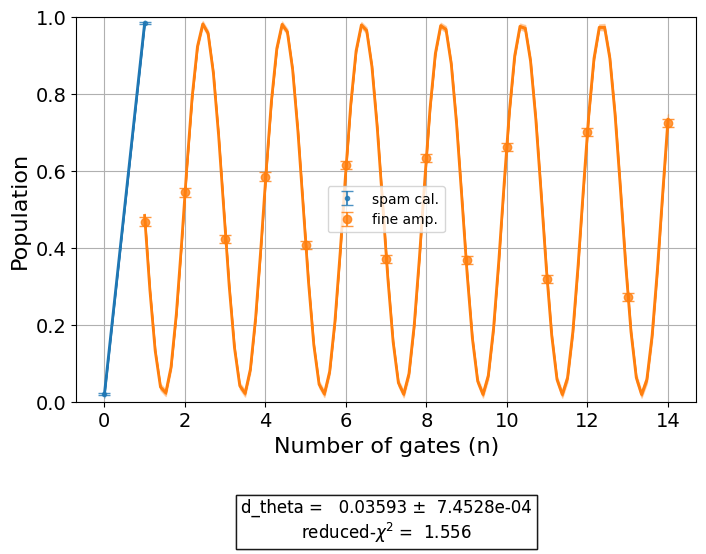

In [123]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 5 pulse x2


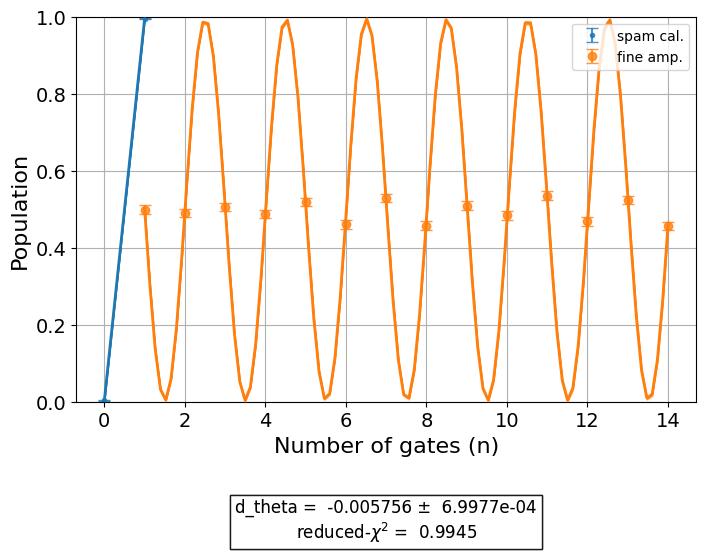

In [124]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 6 pulse x1


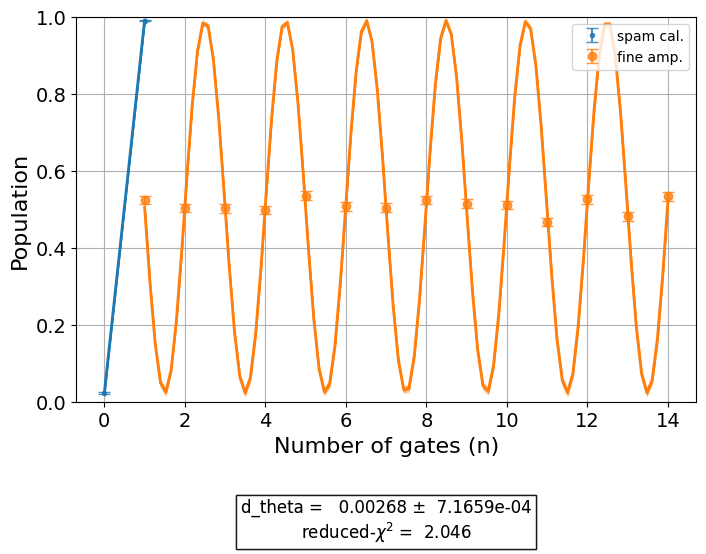

In [125]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 7 pulse x2


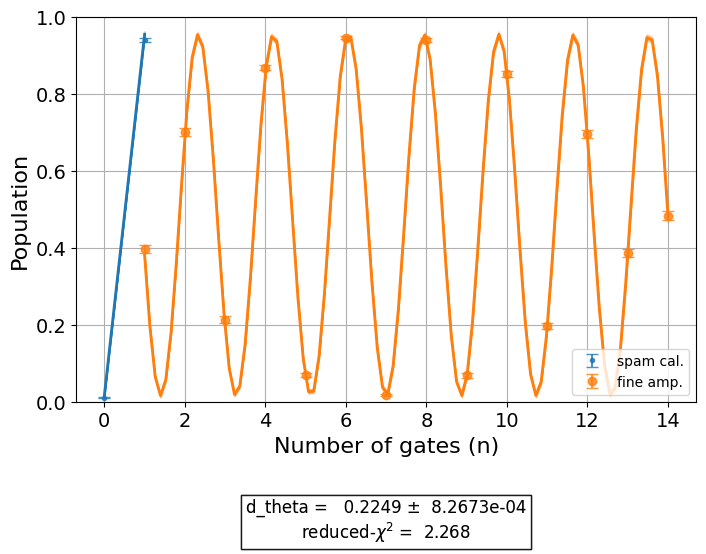

In [126]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

In [175]:
# qubit_index = 4
# print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
# fine_x_exp_datas[qubit_index].figure(0)

In [176]:
# qubit_index = 5
# print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
# fine_x_exp_datas[qubit_index].figure(0)

Qubit 4 pulse sx1


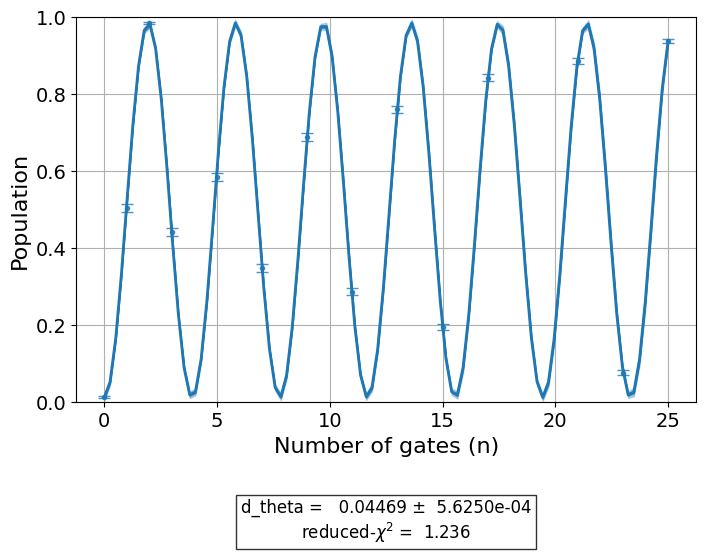

In [127]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 5 pulse sx2


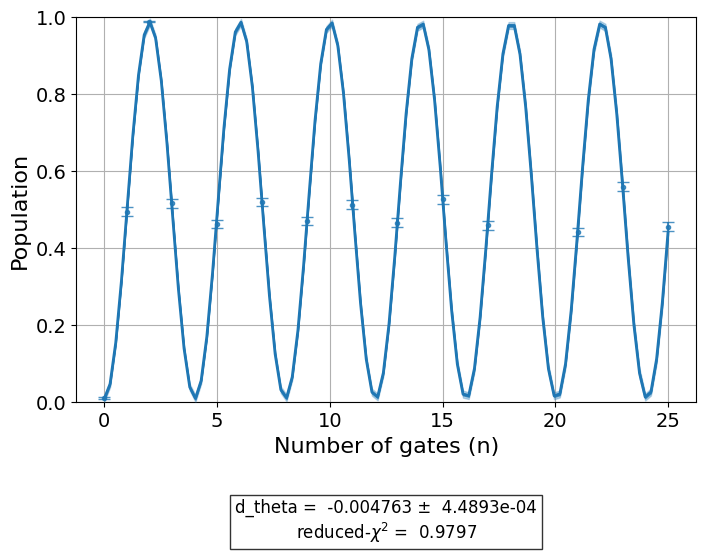

In [128]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 6 pulse sx1


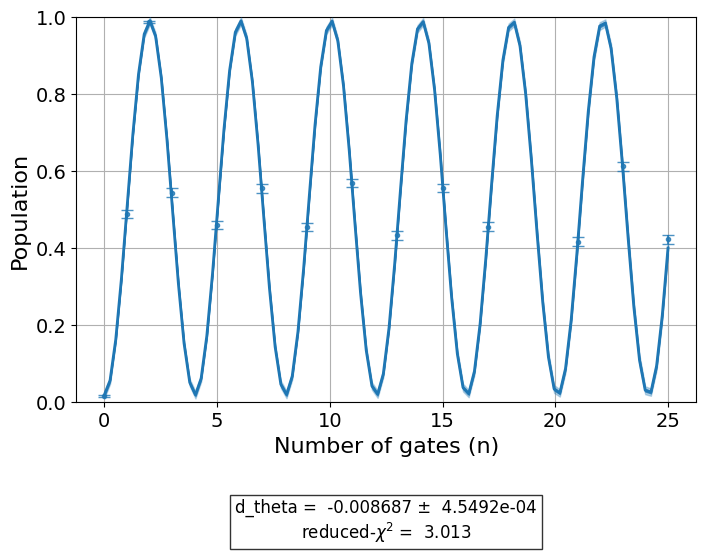

In [129]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 7 pulse sx2


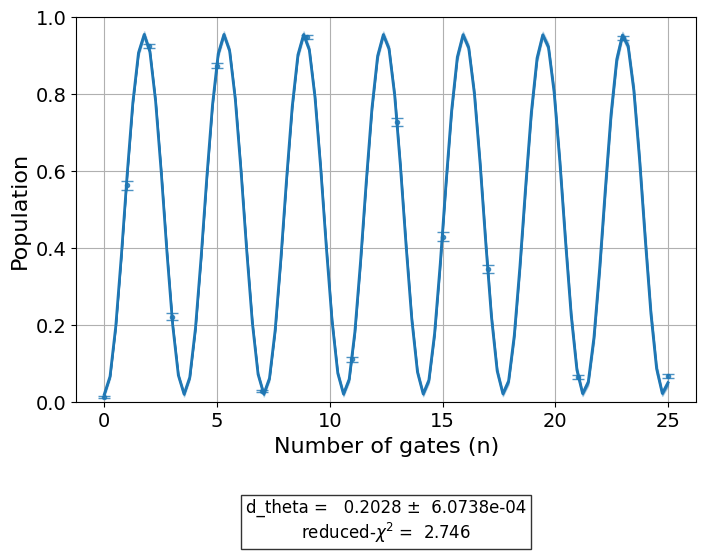

In [130]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

In [285]:
# qubit_index = 4
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [286]:
# qubit_index = 5
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

We can check the amplitude ratios again after the fine calibration.

In [131]:
for i, (qubit, amp) in enumerate(zip(qubits, x_fine_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amplitude: {amp}")

Qubit 4 x1 gate amplitude: 1.6114795824759593
Qubit 5 x2 gate amplitude: 1.75342112748013
Qubit 6 x1 gate amplitude: 1.6603536473141363
Qubit 7 x2 gate amplitude: 1.4519400851090214


In [132]:
for i, (qubit, amp) in enumerate(zip(qubits, sx_fine_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amplitude: {amp}")

Qubit 4 sx1 gate amplitude: 1.6070878582695998
Qubit 5 sx2 gate amplitude: 1.7037799860348946
Qubit 6 sx1 gate amplitude: 1.6756165470204747
Qubit 7 sx2 gate amplitude: 1.3280233317396173


In [133]:
for i, (x_amp, sx_amp) in enumerate(zip(x_fine_amps, sx_fine_amps)):
    print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_amp / x_amp)

Ratio of sx1 to x1 on qubit 4: 0.9972747255043641
Ratio of sx2 to x2 on qubit 5: 0.9716889795228055
Ratio of sx1 to x1 on qubit 6: 1.009192559507445
Ratio of sx2 to x2 on qubit 7: 0.9146543616776723


## DD sequence

We can now play a DD sequence in all the four qubits we calibrated.

In [198]:
fine_q0_x1 = build_schedule(pico_gates["x1"], qubits[0], x_fine_amps[0])
fine_q1_x2 = build_schedule(pico_gates["x2"], qubits[1], x_fine_amps[1])
fine_q2_x1 = build_schedule(pico_gates["x1"], qubits[2], x_fine_amps[2])
fine_q3_x2 = build_schedule(pico_gates["x2"], qubits[3], x_fine_amps[3])
fine_q4_x1 = build_schedule(pico_gates["x1"], qubits[4], x_fine_amps[4])
fine_q5_x2 = build_schedule(pico_gates["x2"], qubits[5], x_fine_amps[5])
fine_q6_x1 = build_schedule(pico_gates["x1"], qubits[6], x_fine_amps[6])
fine_q7_x2 = build_schedule(pico_gates["x2"], qubits[7], x_fine_amps[7])

In [199]:
fine_q0_sx1 = build_schedule(pico_gates["sx1"], qubits[0], sx_fine_amps[0])
fine_q1_sx2 = build_schedule(pico_gates["sx2"], qubits[1], sx_fine_amps[1])
fine_q2_sx1 = build_schedule(pico_gates["sx1"], qubits[2], sx_fine_amps[2])
fine_q3_sx2 = build_schedule(pico_gates["sx2"], qubits[3], sx_fine_amps[3])
fine_q4_sx1 = build_schedule(pico_gates["sx1"], qubits[4], sx_fine_amps[4])
fine_q5_sx2 = build_schedule(pico_gates["sx2"], qubits[5], sx_fine_amps[5])
fine_q6_sx1 = build_schedule(pico_gates["sx1"], qubits[6], sx_fine_amps[6])
fine_q7_sx2 = build_schedule(pico_gates["sx2"], qubits[7], sx_fine_amps[7])

In [200]:
fine_q0_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[0], x_fine_amps_gaussian[0])
fine_q1_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[1], x_fine_amps_gaussian[1])
fine_q2_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[2], x_fine_amps_gaussian[2])
fine_q3_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[3], x_fine_amps_gaussian[3])
fine_q4_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[4], x_fine_amps_gaussian[4])
fine_q5_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[5], x_fine_amps_gaussian[5])
fine_q6_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[6], x_fine_amps_gaussian[6])
fine_q7_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[7], x_fine_amps_gaussian[7])

In [201]:
fine_q0_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[0], sx_fine_amps_gaussian[0])
fine_q1_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[1], sx_fine_amps_gaussian[1])
fine_q2_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[2], sx_fine_amps_gaussian[2])
fine_q3_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[3], sx_fine_amps_gaussian[3])
fine_q4_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[4], sx_fine_amps_gaussian[4])
fine_q5_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[5], sx_fine_amps_gaussian[5])
fine_q6_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[6], sx_fine_amps_gaussian[6])
fine_q7_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[7], sx_fine_amps_gaussian[7])

In [265]:
def xyxy_sequence(repetitions: int, num_qubits: int, all_qubits: list[int], qubit_pairs: list[list[int]], x_schedules = None, sx_schedules = None):
    qc = qk.QuantumCircuit(num_qubits, len(all_qubits))
    qc.reset(all_qubits)

    for q0, q1 in qubit_pairs:
        qc.sx(q0)
        qc.sx(q1)
        for _ in range(repetitions):
            qc.x(q0)
            qc.rz(np.pi, q0)
            qc.x(q0)
            qc.x(q0)
            qc.rz(np.pi, q0)
            qc.x(q0)

            qc.x(q1)
            qc.rz(np.pi, q1)
            qc.x(q1)
            qc.x(q1)
            qc.rz(np.pi, q1)
            qc.x(q1)
        qc.sxdg(q0)
        qc.sxdg(q1)

    qc.barrier()
    
    for (idx, qubit) in enumerate(all_qubits):
        qc.measure(qubit, idx)

    if x_schedules is not None:
        x_gate = qk.circuit.library.XGate()
        for (q0, schedule) in zip(all_qubits, x_schedules):
            qc.add_calibration(x_gate, (q0,), schedule)

    if sx_schedules is not None:
        sx_gate = qk.circuit.library.SXGate()
        for (q0, schedule) in zip(all_qubits, sx_schedules):
            qc.add_calibration(sx_gate, (q0,), schedule)

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [ ]:
xyxy_sequence(
    2, 
    num_qubits, 
    qubits, 
    [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5]], 
    [fine_q0_x1, fine_q1_x2, fine_q2_x1, fine_q3_x2, fine_q4_x1, fine_q5_x2], 
    [fine_q0_sx1, fine_q1_sx2, fine_q2_sx1, fine_q3_sx2, fine_q4_sx1, fine_q5_sx2]
).draw(idle_wires=False)

In [267]:
lengths = list(range(0, 201, 4))
dd_circuits_robust = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], [fine_q0_x1, fine_q1_x2, fine_q2_x1, fine_q3_x2, fine_q4_x1, fine_q5_x2, fine_q6_x1, fine_q7_x2], [fine_q0_sx1, fine_q1_sx2, fine_q2_sx1, fine_q3_sx2, fine_q4_sx1, fine_q5_sx2, fine_q6_sx1, fine_q7_sx2]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], None, None) for i in lengths]
dd_circuits_gaussian = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], [fine_q0_x1_gaussian, fine_q1_x2_gaussian, fine_q2_x1_gaussian, fine_q3_x2_gaussian, fine_q4_x1_gaussian, fine_q5_x2_gaussian], [fine_q0_sx1_gaussian, fine_q1_sx2_gaussian, fine_q2_sx1_gaussian, fine_q3_sx2_gaussian, fine_q4_sx1_gaussian, fine_q5_sx2_gaussian]) for i in lengths]

In [268]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)
dd_jobs_gaussian = sampler.run(dd_circuits_gaussian, shots=2048)

In [552]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id(), dd_jobs_gaussian.job_id()

('cvsg4bskv2vg008d1gwg', 'cvsg4ch9crx0008h2ftg', 'cvsg4d9f8kpg0080hdd0')

In [553]:
dd_jobs_robust.status(), dd_jobs_default.status(), dd_jobs_gaussian.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [546]:
dd_jobs_robust = service.job("cvsg4bskv2vg008d1gwg")
dd_jobs_default = service.job("cvsg4ch9crx0008h2ftg")
dd_jobs_gaussian = service.job("cvsg4d9f8kpg0080hdd0")

In [554]:
robust_results = dd_jobs_robust.result()
robust_counts = []
for result in robust_results:
    robust_counts.append(result.data.c.get_counts())

default_results = dd_jobs_default.result()
default_counts = []
for result in default_results:
    default_counts.append(result.data.c.get_counts())

gaussian_results = dd_jobs_gaussian.result()
gaussian_counts = []
for result in gaussian_results:
    gaussian_counts.append(result.data.c.get_counts())

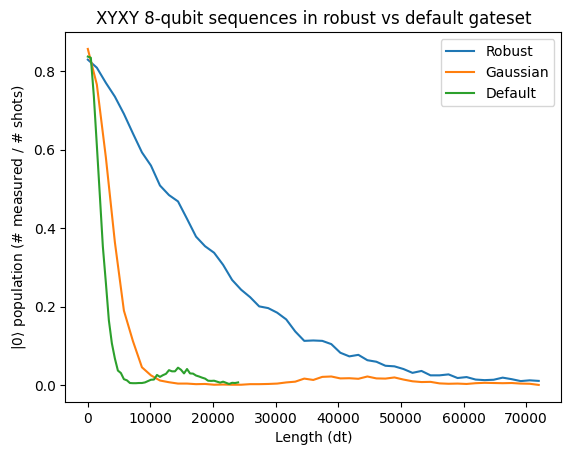

In [555]:
robust_points = [count.get("00000000", 0) / 2048 for count in robust_counts]
default_points = [count.get("00000000", 0) / 2048 for count in default_counts]
gaussian_points = [count.get("00000000", 0) / 2048 for count in gaussian_counts]

plt.plot([l * duration for l in lengths], robust_points, label="Robust")
plt.plot([l * duration for l in lengths], gaussian_points, label="Gaussian")
plt.plot([l * 120 for l in lengths], default_points, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")
plt.title("XYXY 8-qubit sequences in robust vs default gateset")
plt.legend()
plt.show()

In [558]:
sliced_robust_counts = []
for result in robust_results:
    sliced_robust_counts.append(result.data.c.slice_bits([0, 1]).get_counts())

sliced_gaussian_counts = []
for result in gaussian_results:
    sliced_gaussian_counts.append(result.data.c.slice_bits([0, 1]).get_counts())

sliced_default_counts = []
for result in default_results:
    sliced_default_counts.append(result.data.c.slice_bits([0, 1]).get_counts())

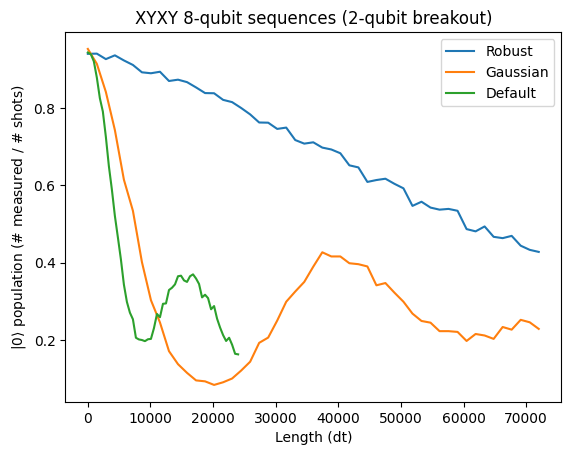

In [559]:
sliced_robust_points = [count.get("00", 0) / 2048 for count in sliced_robust_counts]
sliced_default_points = [count.get("00", 0) / 2048 for count in sliced_default_counts]
sliced_gaussian_points = [count.get("00", 0) / 2048 for count in sliced_gaussian_counts]

plt.plot([l * duration for l in lengths], sliced_robust_points, label="Robust")
plt.plot([l * duration for l in lengths], sliced_gaussian_points, label="Gaussian")
plt.plot([l * 120 for l in lengths], sliced_default_points, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")
plt.title("XYXY 8-qubit sequences (2-qubit breakout)")
plt.legend()
plt.show()

## Testing robust ID

In [ ]:
plt.plot(pico_gates["i2"]);

For the amplitude of the identity gate, we choose the amplitude of either the corresponding x or sx gate in the same qubit

In [189]:
id_amp_q0 = x_fine_amps[0]
id_amp_q1 = x_fine_amps[1]
id_amp_q2 = x_fine_amps[2]
id_amp_q3 = x_fine_amps[3]
id_amp_q4 = x_fine_amps[4]
id_amp_q5 = x_fine_amps[5]
id_amp_q6 = x_fine_amps[6]
id_amp_q7 = x_fine_amps[7]

In [190]:
q0_i2 = build_schedule(pico_gates["i2"], qubit0, id_amp_q0)
q1_i2 = build_schedule(pico_gates["i2"], qubit1, id_amp_q1)
q2_i2 = build_schedule(pico_gates["i2"], qubit2, id_amp_q2)
q3_i2 = build_schedule(pico_gates["i2"], qubit3, id_amp_q3)
q4_i2 = build_schedule(pico_gates["i2"], qubit4, id_amp_q4)
q5_i2 = build_schedule(pico_gates["i2"], qubit5, id_amp_q5)
q6_i2 = build_schedule(pico_gates["i2"], qubit6, id_amp_q6)
q7_i2 = build_schedule(pico_gates["i2"], qubit7, id_amp_q7)

In [ ]:
def build_empty_sched(qubit: int, duration: int):
    with qk.pulse.build(backend=backend) as sched:
        qk.pulse.delay(duration, qk.pulse.DriveChannel(qubit))
    return sched
build_empty_sched(qubit0, duration).draw()

In [192]:
q0_i1 = build_empty_sched(qubit0, duration)
q1_i1 = build_empty_sched(qubit1, duration)
q2_i1 = build_empty_sched(qubit2, duration)
q3_i1 = build_empty_sched(qubit3, duration)
q4_i1 = build_empty_sched(qubit4, duration)
q5_i1 = build_empty_sched(qubit5, duration)
q6_i1 = build_empty_sched(qubit6, duration)
q7_i1 = build_empty_sched(qubit7, duration)

In [193]:
def build_id_sequence(repetitions: int, num_qubits: int, all_qubits: list[int], qubit_pairs: list[list[int]], schedules: list = None):
    qc = qk.QuantumCircuit(num_qubits, len(all_qubits))
    
    qc.reset(all_qubits)

    for q0, q1 in qubit_pairs:
        qc.sx(q0)
        qc.sx(q1)
        for _ in range(repetitions):
            qc.id(q0)
            qc.id(q1)

        qc.sxdg(q0)
        qc.sxdg(q1)

    qc.barrier()

    for (idx, qubit) in enumerate(all_qubits):
        qc.measure(qubit, idx)

    if schedules is not None:
        gate = qk.circuit.library.IGate()
        for (q0, schedule) in zip(all_qubits, schedules):
            qc.add_calibration(gate, (q0,), schedule)

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [ ]:
build_id_sequence(10, num_qubits, qubits[0:2], [[qubit0, qubit1]], [q0_i1, q1_i2]).draw(idle_wires=False)

In [89]:
lengths = list(range(0, 201, 4))
id_circuits_robust = [build_id_sequence(i, num_qubits, qubits[0:2], [[qubit0, qubit1]], [q0_i1, q1_i2]) for i in lengths]
id_circuits_robust_flip = [build_id_sequence(i, num_qubits, qubits[0:2], [[qubit0, qubit1]], [q0_i2, q1_i1]) for i in lengths]
id_circuits_default = [build_id_sequence(i, num_qubits, qubits[0:2], [[qubit0, qubit1]], None) for i in lengths]

In [90]:
id_jobs_robust = sampler.run(id_circuits_robust, shots=2048)
id_jobs_robust_flip = sampler.run(id_circuits_robust_flip, shots=2048)
id_jobs_default = sampler.run(id_circuits_default, shots=2048)

In [ ]:
id_jobs_robust.job_id(), id_jobs_robust_flip.job_id(), id_jobs_default.job_id()

In [ ]:
id_jobs_robust.status(), id_jobs_robust_flip.status(), id_jobs_default.status()

In [99]:
id_jobs_robust = service.job("cvg66yb8w2g0008ejhzg")
id_jobs_robust_flip = service.job("cvg66yvkmd100082jyr0")
id_jobs_default = service.job("cvg66zbvawwg0089aw70")

In [117]:
id_robust_results = id_jobs_robust.result()
id_robust_counts = []
for result in id_robust_results:
    id_robust_counts.append(result.data.c.get_counts())

id_robust_flip_results = id_jobs_robust_flip.result()
id_robust_flip_counts = []
for result in id_robust_flip_results:
    id_robust_flip_counts.append(result.data.c.get_counts())

id_default_results = id_jobs_default.result()
id_default_counts = []
for result in id_default_results:
    id_default_counts.append(result.data.c.get_counts())

In [ ]:
robust_11 = [count.get("00", 0) / 2048 for count in id_robust_counts]
robust_flip_11 = [count.get("00", 0) / 2048 for count in id_robust_flip_counts]
default_11 = [count.get("00", 0) / 2048 for count in id_default_counts]

plt.plot([l * duration for l in lengths], robust_11, label="Robust")
plt.plot([l * duration for l in lengths], robust_flip_11, label="Robust flip")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("00 population (# measured / # shots)")
plt.title("II Sequences in robust vs default gateset")
plt.legend()
plt.show()

## Simultaneous single-qubit RB

In [223]:
def get_rb_experiment(qubit: int, lengths, num_samples, schedules = None, random_seed = None):
    inst_map = qk.pulse.InstructionScheduleMap()
    if schedules is not None:
        inst_map.add(qk.circuit.library.XGate(), (qubit,), schedules[0])
        inst_map.add(qk.circuit.library.SXGate(), (qubit,), schedules[1])
        inst_map.add(qk.circuit.library.IGate(), (qubit,), schedules[2])
    exp = qk_e.library.StandardRB((qubit0,), lengths=lengths, num_samples=num_samples, seed = random_seed)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

In [641]:
rb_lengths = np.arange(1, 800, 100)
num_samples = 10

In [225]:
all_schedules = [
    [fine_q0_x1, fine_q0_sx1, q0_i1],
    [fine_q1_x2, fine_q1_sx2, q1_i2],
    [fine_q2_x1, fine_q2_sx1, q2_i1],
    [fine_q3_x2, fine_q3_sx2, q3_i2],
    # [fine_q4_x1, fine_q4_sx1, q4_i1],
    # [fine_q5_x2, fine_q5_sx2, q5_i2],
    # [fine_q6_x1, fine_q6_sx1, q6_i1],
    # [fine_q7_x2, fine_q7_sx2, q7_i2]
]

gaussian_schedules = [
    [fine_q0_x1_gaussian, fine_q0_sx1_gaussian, q0_i1],
    [fine_q1_x2_gaussian, fine_q1_sx2_gaussian, q1_i1],
    [fine_q2_x1_gaussian, fine_q2_sx1_gaussian, q2_i1],
    [fine_q3_x2_gaussian, fine_q3_sx2_gaussian, q3_i1],
]

rb_qubits = [qubit0, qubit1, qubit2, qubit3] #, qubit4, qubit5, qubit6, qubit7]

In [226]:
rb_experiments = []

for (qubit, schedules) in zip(rb_qubits, all_schedules):
    rb_experiments.append(get_rb_experiment(qubit, rb_lengths, num_samples, schedules, random_seed=12345))

In [ ]:
qk.transpile(rb_experiments[1].circuits()[12], basis_gates=["x", "sx", "rz", "id"]).draw(idle_wires=False)

In [228]:
num_circuits = len(rb_experiments[0].circuits())
rb_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(num_circuits)]
rb_crs = [qk.ClassicalRegister(len(rb_qubits), "c") for _ in range(num_circuits)]
rb_circuits = [qk.QuantumCircuit(rb_qrs[i], rb_crs[i]) for i in range(num_circuits)]

rb_default_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(num_circuits)]
rb_default_crs = [qk.ClassicalRegister(len(rb_qubits), "c") for _ in range(num_circuits)]
rb_default_circuits = [qk.QuantumCircuit(rb_default_qrs[i], rb_default_crs[i]) for i in range(num_circuits)]

rb_gaussian_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(num_circuits)]
rb_gaussian_crs = [qk.ClassicalRegister(len(rb_qubits), "c") for _ in range(num_circuits)]
rb_gaussian_circuits = [qk.QuantumCircuit(rb_gaussian_qrs[i], rb_gaussian_crs[i]) for i in range(num_circuits)]

for i, qubit in enumerate(rb_qubits):
    rb_q_circuits = rb_experiments[i].circuits()
    qubit_schedules = all_schedules[i]
    gaussian_qubit_schedules = gaussian_schedules[i]

    for j in range(num_circuits):
        rb_circuits[j].append(rb_q_circuits[j], qargs=(rb_qrs[j][qubit],), cargs=(rb_crs[j][i],))
        rb_default_circuits[j].append(rb_q_circuits[j], qargs=(rb_default_qrs[j][qubit],), cargs=(rb_default_crs[j][i],))
        rb_gaussian_circuits[j].append(rb_q_circuits[j], qargs=(rb_gaussian_qrs[j][qubit],), cargs=(rb_gaussian_crs[j][i],))
        
        rb_circuits[j].add_calibration(qk.circuit.library.XGate(), (qubit,), qubit_schedules[0])
        rb_circuits[j].add_calibration(qk.circuit.library.SXGate(), (qubit,), qubit_schedules[1])
        rb_circuits[j].add_calibration(qk.circuit.library.IGate(), (qubit,), qubit_schedules[2])

        rb_gaussian_circuits[j].add_calibration(qk.circuit.library.XGate(), (qubit,), gaussian_qubit_schedules[0])
        rb_gaussian_circuits[j].add_calibration(qk.circuit.library.SXGate(), (qubit,), gaussian_qubit_schedules[1])
        rb_gaussian_circuits[j].add_calibration(qk.circuit.library.IGate(), (qubit,), gaussian_qubit_schedules[2])

rb_circuits = [qk.transpile(circuit, basis_gates=["x", "sx", "rz", "id"]) for circuit in rb_circuits]
rb_default_circuits = [qk.transpile(circuit, basis_gates=["x", "sx", "rz", "id"]) for circuit in rb_default_circuits]
rb_gaussian_circuits = [qk.transpile(circuit, basis_gates=["x", "sx", "rz", "id"]) for circuit in rb_gaussian_circuits]

In [229]:
for circuit in rb_circuits:
    circuit.remove_final_measurements()
    circuit.add_register(qk.ClassicalRegister(len(rb_qubits), "m"))
    circuit.barrier()
    circuit.measure(rb_qubits, [i for i in range(len(rb_qubits))])

for circuit in rb_default_circuits:
    circuit.remove_final_measurements()
    circuit.add_register(qk.ClassicalRegister(len(rb_qubits), "m"))
    circuit.barrier()
    circuit.measure(rb_qubits, [i for i in range(len(rb_qubits))])

for circuit in rb_gaussian_circuits:
    circuit.remove_final_measurements()
    circuit.add_register(qk.ClassicalRegister(len(rb_qubits), "m"))
    circuit.barrier()
    circuit.measure(rb_qubits, [i for i in range(len(rb_qubits))])

In [ ]:
rb_circuits[0].draw(idle_wires=False)

In [231]:
rb_jobs = sampler.run(rb_circuits, shots=2048)
rb_default_jobs = sampler.run(rb_default_circuits, shots=2048)
rb_gaussian_jobs = sampler.run(rb_gaussian_circuits, shots=2048)

In [ ]:
rb_jobs.job_id(), rb_default_jobs.job_id(), rb_gaussian_jobs.job_id()

In [ ]:
rb_jobs.status(), rb_default_jobs.status(), rb_gaussian_jobs.status()

In [265]:
rb_jobs = service.job("cvy2s4cwqn10008w5g5g")
rb_default_jobs = service.job("cvy2s5c5e7xg008tyz50")
rb_gaussian_jobs = service.job("cvy2s64fd8tg008xdf90")

In [266]:
rb_metadata = []
for i in range(num_circuits):
    metadata = rb_experiments[0].circuits()[i].metadata
    rb_metadata.append(metadata)

In [267]:
def reconstruct_rb_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]]):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            counts = get_qubit_counts(result.data.m.get_counts(), qubits.index(qubit), num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.set_options(gate_error_ratio=None)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [268]:
rb_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
)

rb_default_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_default_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
)

rb_gaussian_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_gaussian_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
)

In [518]:
robust_alphas = []
gaussian_alphas = []
default_alphas = []

robust_epc = []
gaussian_epc = []
default_epc = []

for i in range(len(rb_data)):
    print(f"Qubit {qubits[i]} RB data:")
    print("    Robust alpha:", rb_data[i].analysis_results("alpha").value.nominal_value)
    print("    Robust EPC:", rb_data[i].analysis_results("EPC").value.nominal_value)

    robust_alphas.append(rb_data[i].analysis_results("alpha").value.nominal_value)
    robust_epc.append(rb_data[i].analysis_results("EPC").value.nominal_value)

    print()
    print("    Gaussian alpha:", rb_gaussian_data[i].analysis_results("alpha").value.nominal_value)
    print("    Gaussian EPC:", rb_gaussian_data[i].analysis_results("EPC").value.nominal_value)

    gaussian_alphas.append(rb_gaussian_data[i].analysis_results("alpha").value.nominal_value)
    gaussian_epc.append(rb_gaussian_data[i].analysis_results("EPC").value.nominal_value)

    print()
    print("    Default alpha:", rb_default_data[i].analysis_results("alpha").value.nominal_value)
    print("    Default EPC:", rb_default_data[i].analysis_results("EPC").value.nominal_value)

    default_alphas.append(rb_default_data[i].analysis_results("alpha").value.nominal_value)
    default_epc.append(rb_default_data[i].analysis_results("EPC").value.nominal_value)

Qubit 3 RB data:
    Robust alpha: 0.9933625933341852
    Robust EPC: 0.0033187033329074023

    Gaussian alpha: 0.9978936840415651
    Gaussian EPC: 0.0010531579792174561

    Default alpha: 0.9992254909457624
    Default EPC: 0.0003872545271187966
Qubit 4 RB data:
    Robust alpha: 0.9958184200272807
    Robust EPC: 0.0020907899863596424

    Gaussian alpha: 0.9983845460943352
    Gaussian EPC: 0.0008077269528323772

    Default alpha: 0.997530002529178
    Default EPC: 0.001234998735410997
Qubit 5 RB data:
    Robust alpha: 0.9969058934070082
    Robust EPC: 0.0015470532964959038

    Gaussian alpha: 0.9989225895514946
    Gaussian EPC: 0.0005387052242527002

    Default alpha: 0.9994311414446873
    Default EPC: 0.0002844292776563728
Qubit 6 RB data:
    Robust alpha: 0.9922248529072867
    Robust EPC: 0.0038875735463566596

    Gaussian alpha: 0.9995475946239425
    Gaussian EPC: 0.00022620268802875376

    Default alpha: 0.9997516758258953
    Default EPC: 0.00012416208705234855


In [519]:
np.average(robust_alphas), np.average(gaussian_alphas), np.average(default_alphas)

(0.9945779399189403, 0.9986871035778344, 0.9989845776863808)

In [520]:
np.average(robust_epc), np.average(gaussian_epc), np.average(default_epc)

(0.002711030040529902, 0.0006564482110828218, 0.0005077111568096287)

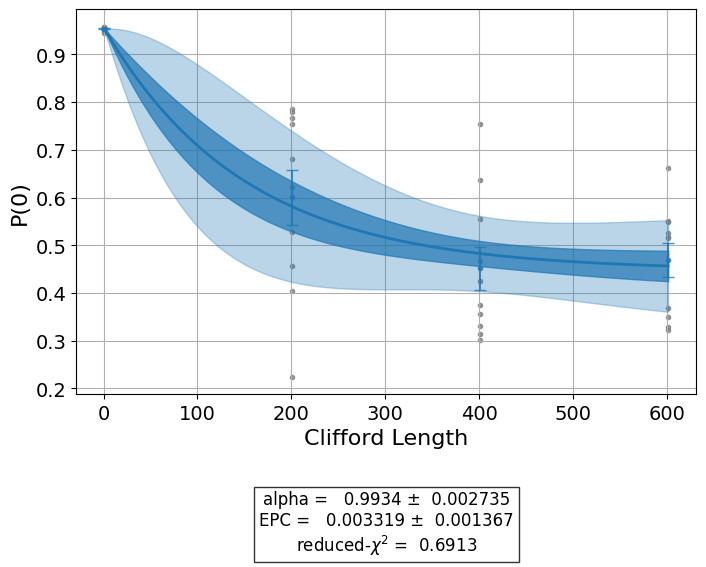

In [521]:
rb_data[0].block_for_results()
rb_data[0].figure(0)

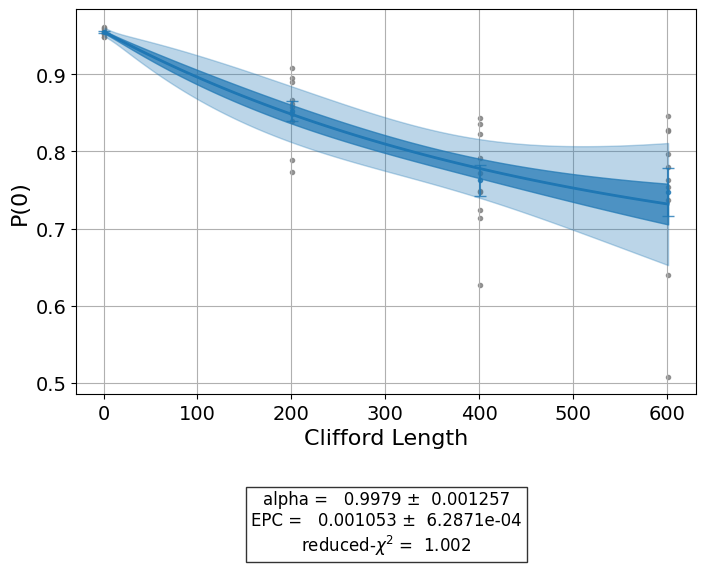

In [522]:
rb_gaussian_data[0].block_for_results()
rb_gaussian_data[0].figure(0)

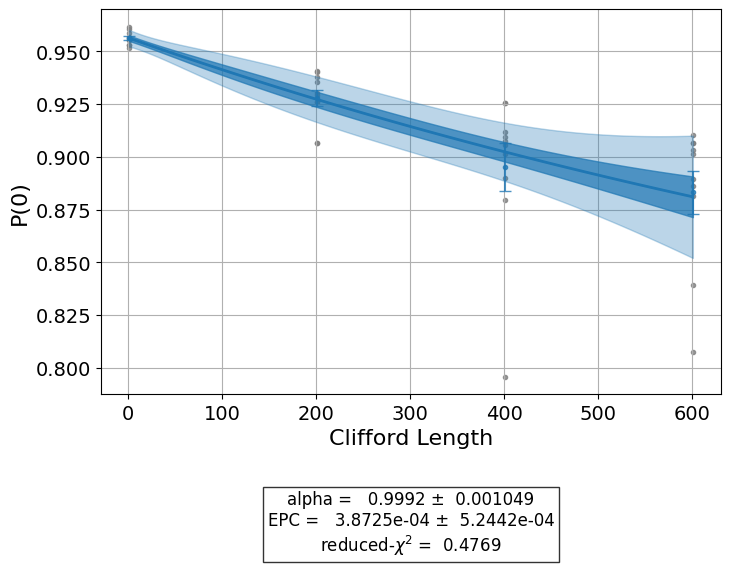

In [523]:
rb_default_data[0].block_for_results()
rb_default_data[0].figure(0)

## Comparison to isolated RB

We compare the decay curve for one of the qubits in the simultanous RB experiment to the decay curve for the same RB experiment in isolation.

In [575]:
qubit_for_rb_data = 1

In [576]:
robust_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, all_schedules[qubit_for_rb_data], random_seed=12345)
gaussian_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, gaussian_schedules[qubit_for_rb_data], random_seed=12345)
default_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, None, random_seed=12345)

In [ ]:
robust_iso_job = robust_iso_rb.run(backend=backend, shots=2048)
gaussian_iso_job = gaussian_iso_rb.run(backend=backend, shots=2048)
default_iso_job = default_iso_rb.run(backend=backend, shots=2048)

In [639]:
robust_iso_job.job_ids[0], gaussian_iso_job.job_ids[0], default_iso_job.job_ids[0]

('cvy6z44fd8tg008xdxv0', 'cvy6zc5fd8tg008xdxvg', 'cvy6zexh0nm00088dxq0')

In [640]:
robust_iso_job.jobs()[0].status(), gaussian_iso_job.jobs()[0].status(), default_iso_job.jobs()[0].status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [631]:
from qiskit_experiments.framework import ExperimentData

robust_iso_data = ExperimentData(experiment=robust_iso_rb)
robust_iso_data.add_jobs([service.job("cvy6z44fd8tg008xdxv0")])
robust_iso_rb.analysis.run(robust_iso_data, replace_results=True)

gaussian_iso_data = ExperimentData(experiment=gaussian_iso_rb)
gaussian_iso_data.add_jobs([service.job("cvy6zc5fd8tg008xdxvg")])
gaussian_iso_rb.analysis.run(gaussian_iso_data, replace_results=True)

default_iso_data = ExperimentData(experiment=default_iso_rb)
default_iso_data.add_jobs([service.job("cvy6zexh0nm00088dxq0")])
default_iso_rb.analysis.run(default_iso_data, replace_results=True);

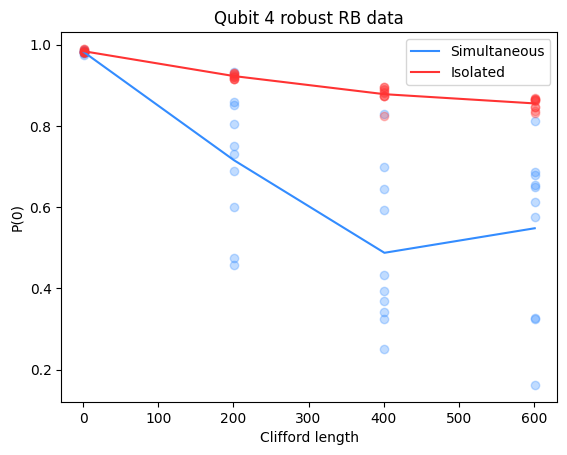

In [635]:
p0_robust = {}
for d in rb_data[qubit_for_rb_data].data():
    if d["metadata"]["xval"] not in p0_robust:
        p0_robust[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_robust[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_robust_iso = {}
for d in robust_iso_data.data():
    if d["metadata"]["xval"] not in p0_robust_iso:
        p0_robust_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_robust_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

plt.plot(p0_robust.keys(), [np.average(v) for v in p0_robust.values()], label="Simultaneous", c="#338cff")
for key in p0_robust.keys():
    plt.scatter([key] * len(p0_robust[key]), p0_robust[key], alpha=0.3, c="#338cff")

plt.plot(p0_robust_iso.keys(), [np.average(v) for v in p0_robust_iso.values()], label="Isolated", c="#ff3333")
for key in p0_robust_iso.keys():
    plt.scatter([key] * len(p0_robust_iso[key]), p0_robust_iso[key], alpha=0.3, c="#ff3333")

plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} robust RB data")
plt.ylabel("P(0)")
plt.xlabel("Clifford length")
plt.legend();

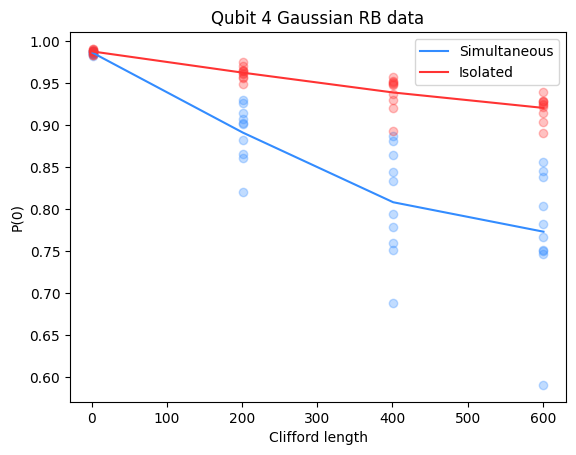

In [634]:
p0_gaussian = {}
for d in rb_gaussian_data[qubit_for_rb_data].data():
    if d["metadata"]["xval"] not in p0_gaussian:
        p0_gaussian[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_gaussian[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_gaussian_iso = {}
for d in gaussian_iso_data.data():
    if d["metadata"]["xval"] not in p0_gaussian_iso:
        p0_gaussian_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_gaussian_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

plt.plot(p0_gaussian.keys(), [np.average(v) for v in p0_gaussian.values()], label="Simultaneous", c="#338cff")
for key in p0_gaussian.keys():
    plt.scatter([key] * len(p0_gaussian[key]), p0_gaussian[key], alpha=0.3, c="#338cff")

plt.plot(p0_gaussian_iso.keys(), [np.average(v) for v in p0_gaussian_iso.values()], label="Isolated", c="#ff3333")
for key in p0_gaussian_iso.keys():
    plt.scatter([key] * len(p0_gaussian_iso[key]), p0_gaussian_iso[key], alpha=0.3, c="#ff3333")

plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} Gaussian RB data")
plt.ylabel("P(0)")
plt.xlabel("Clifford length")
plt.legend();

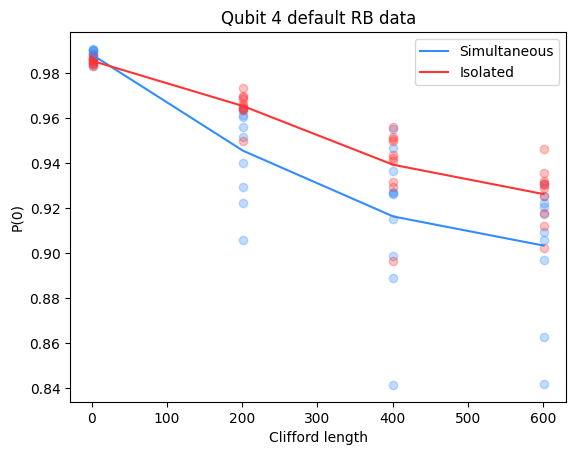

In [638]:
p0_default = {}
for d in rb_default_data[qubit_for_rb_data].data():
    if d["metadata"]["xval"] not in p0_default:
        p0_default[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_default[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_default_iso = {}
for d in default_iso_data.data():
    if d["metadata"]["xval"] not in p0_default_iso:
        p0_default_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_default_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

plt.plot(p0_default.keys(), [np.average(v) for v in p0_default.values()], label="Simultaneous", c="#338cff")
for key in p0_default.keys():
    plt.scatter([key] * len(p0_default[key]), p0_default[key], alpha=0.3, c="#338cff")

plt.plot(p0_default_iso.keys(), [np.average(v) for v in p0_default_iso.values()], label="Isolated", c="#ff3333")
for key in p0_default_iso.keys():
    plt.scatter([key] * len(p0_default_iso[key]), p0_default_iso[key], alpha=0.3, c="#ff3333")

plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} default RB data")
plt.ylabel("P(0)")
plt.xlabel("Clifford length")
plt.legend();

## Custom ECR

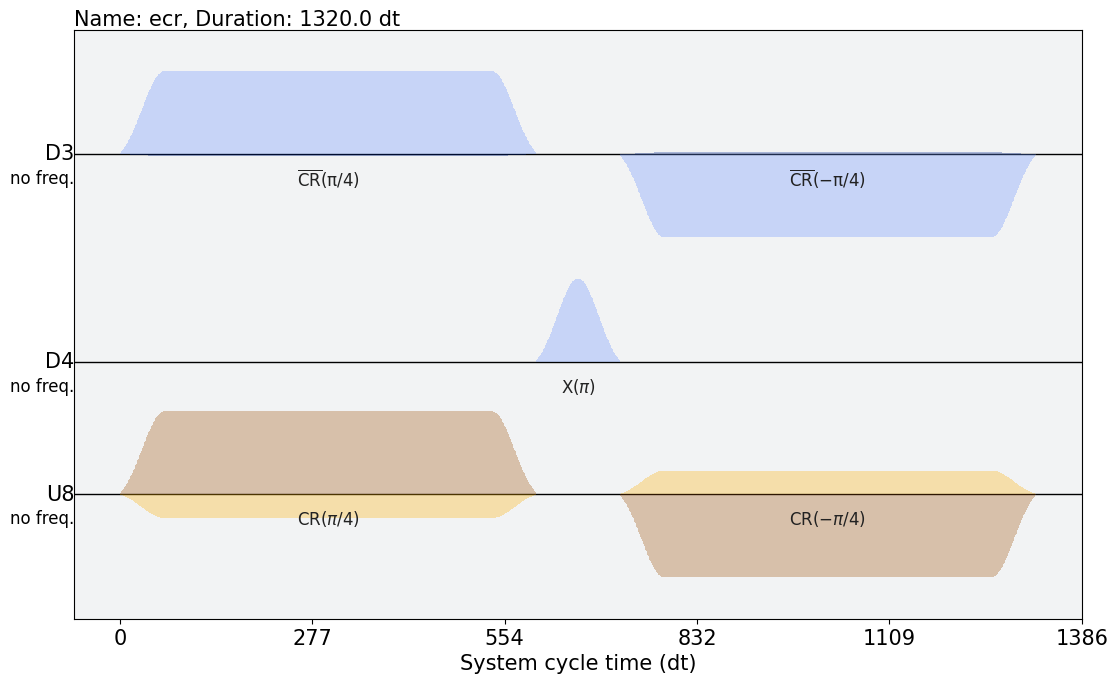

In [528]:
ecr_sched = backend.instruction_schedule_map.get("ecr", (qubit1, qubit0))
ecr_sched.draw()

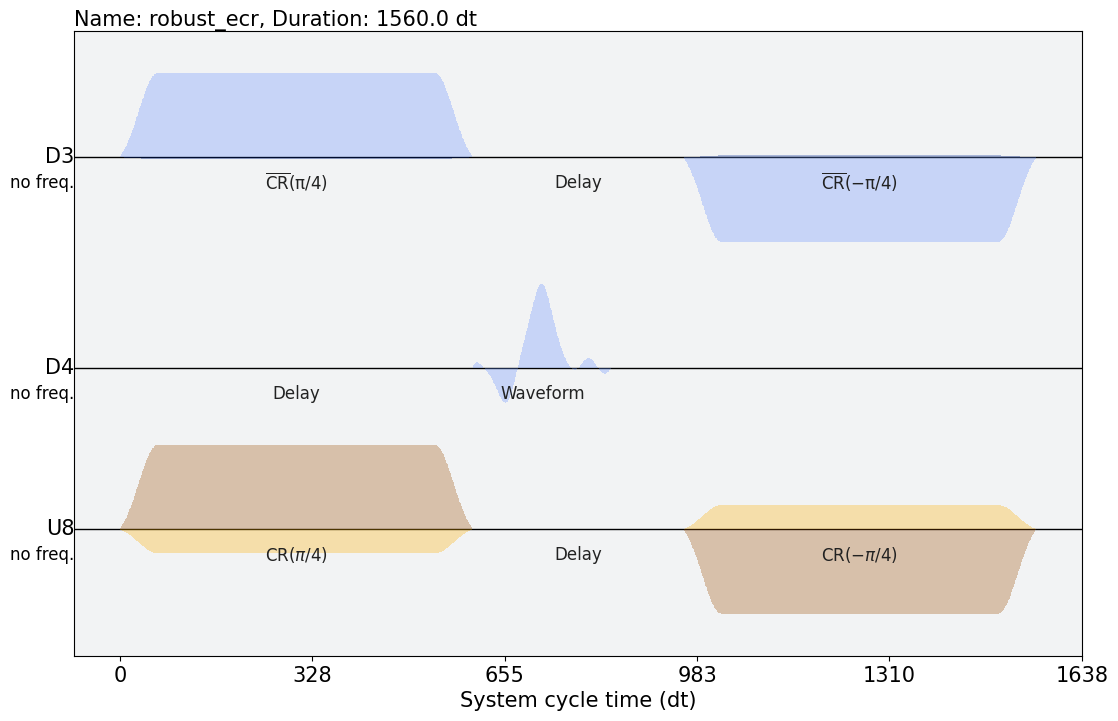

In [529]:
def get_robust_ecr(x_sched, q0, original_ecr):
    with qk.pulse.build(name=f"robust_ecr", backend=backend) as sched:
        sched.append(original_ecr.instructions[0][1])
        sched.append(original_ecr.instructions[1][1])
        
        qk.pulse.delay(original_ecr.instructions[0][1].duration, qk.pulse.DriveChannel(q0))
        sched.append(x_sched)
        qk.pulse.delay(duration, original_ecr.instructions[3][1].channel)
        qk.pulse.delay(duration, original_ecr.instructions[4][1].channel)
        

        sched.append(original_ecr.instructions[3][1])
        sched.append(original_ecr.instructions[4][1])

    return sched

robust_ecr = get_robust_ecr(fine_q1_x2, qubit1, ecr_sched)
robust_ecr.draw()

In [530]:
default_ecr_q1_q0 = backend.instruction_schedule_map.get("ecr", (qubit1, qubit0))
default_ecr_q1_q2 = backend.instruction_schedule_map.get("ecr", (qubit1, qubit2))
default_ecr_q3_q2 = backend.instruction_schedule_map.get("ecr", (qubit3, qubit2))

robust_ecr_q1_q0 = get_robust_ecr(fine_q1_x2, qubit1, default_ecr_q1_q0)
robust_ecr_q1_q2 = get_robust_ecr(fine_q1_x2, qubit1, default_ecr_q1_q2)
robust_ecr_q3_q2 = get_robust_ecr(fine_q3_x2, qubit3, default_ecr_q3_q2)

gaussian_ecr_q1_q0 = get_robust_ecr(fine_q1_x2_gaussian, qubit1, default_ecr_q1_q0)
gaussian_ecr_q1_q2 = get_robust_ecr(fine_q1_x2_gaussian, qubit1, default_ecr_q1_q2)
gaussian_ecr_q3_q2 = get_robust_ecr(fine_q3_x2_gaussian, qubit3, default_ecr_q3_q2)

## Transverse Ising model

In [531]:
from typing import Union

class TransverseIsingModel:
    def __init__(
        self,
        num_qubits: int,
        quantum_registers: list[int] = [],
        classical_registers: list[int] = [],
        hz: float = 2 * np.pi,
        Jx: float = 2 * np.pi,
        Δt: float = 0.05,
    ):
        """
        Initialize the transverse Ising model.

        Args:
            num_qubit_registers (int): number of qubits in the register
            num_classical_registers (int): number of classical registers
            hz (float): magnetic field along z
            Jx (float): Coupling along x
            Δt (float): time step for integration
        """
        self._N = num_qubits
        self._quantum_registers = quantum_registers
        self._C = len(classical_registers)
        self._hz = hz
        self._Jx = Jx
        self._Δt = Δt

    def create_initial_state(self, num_qubits: int, qr: list[int], cr: int):
        """
        Creates the initial state for the experiment.
        Here we would like to prepare the |+>|+>|+>|+> state.
        """
        circ = qk.QuantumCircuit(num_qubits, cr)
        [circ.h(i) for i in qr]
        return circ

    def rxx(self, circ: qk.QuantumCircuit, θx, q1: int, q2: int):
        """
        Implements the exp(-i theta/2 sx_1 sx_2) gate.
        """
        circ.cx(q1, q2)
        circ.rx(θx, q1)
        circ.cx(q1, q2)
        return circ

    def first_order_Trotter_unitary(
        self, circ: Union[qk.QuantumCircuit, None] = None, barrier=False
    ):
        """
        Applies a Unitary for a single time step U(Δt) using first-order trotter
            expansion to the input quantum circuit.

        input : circ is a quantum circuit
        output : circ-U(Δt)-
        """
        # Initial circuit
        if circ is None:
            circ = self.create_initial_state(self._N, self._quantum_registers, self._C)

        # Layer A: coupling XX between n and n+1
        # Induce parallel CR gates
        if barrier:
            circ.barrier()
        for p in range(0, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt, self._quantum_registers[p], self._quantum_registers[p + 1]
            )
        if barrier:
            circ.barrier()
        for p in range(1, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt, self._quantum_registers[p], self._quantum_registers[p + 1]
            )

        # Layer B: on-site Z
        for p in range(len(self._quantum_registers)):
            circ.rz(self._hz * self._Δt, self._quantum_registers[p])

        return circ

    def second_order_Trotter_unitary(
        self, circ: Union[qk.QuantumCircuit, None] = None, barrier=False, measure=True
    ):
        """
        Applies a Unitary for a single time step U(Δt) using the second-order trotter
            expansion to the input quantum circuit.

        input : circ is a quantum circuit
        output : circ-U(Δt)-
        """
        # Initial circuit
        if circ is None:
            circ = self.create_initial_state(self._N, self._quantum_registers, self._C)

        # Layer 2: on-site Z (half)
        for p in range(len(self._quantum_registers)):
            circ.rz(self._hz * self._Δt / 2, self._quantum_registers[p])

        # Layer 1: coupling XX between n and n+1
        # Induce parallel structure (and symmetry)
        for p in range(1, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt / 2, self._quantum_registers[p], self._quantum_registers[p + 1]
            )
        # Add barriers to separate the parallel section
        if barrier:
            circ.barrier()
        for p in range(0, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt, self._quantum_registers[p], self._quantum_registers[p + 1]
            )
        if barrier:
            circ.barrier()
        for p in range(1, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt / 2, self._quantum_registers[p], self._quantum_registers[p + 1]
            )

        # Layer 2: on-site Z (half)
        for p in range(len(self._quantum_registers)):
            circ.rz(self._hz * self._Δt / 2, self._quantum_registers[p])

        # Measurement
        if measure:
            circ.barrier()
            for p in range(len(self._quantum_registers)):
                circ.measure(self._quantum_registers[p], p)

        return circ

In [532]:
ising = TransverseIsingModel(num_qubits, [qubit0, qubit1, qubit2, qubit3], [0, 1, 2, 3])
ising_circuit = ising.second_order_Trotter_unitary()
ising_circuit = qk.transpile(ising_circuit, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)
ising_circuit.draw(idle_wires=False)

global phase: π/4
         ┌──────────┐┌────┐┌─────────────┐┌────┐┌─────────┐                 »
q_3 -> 3 ┤ Rz(-π/2) ├┤ √X ├┤ Rz(-1.7279) ├┤ √X ├┤ Rz(π/2) ├─────────────────»
         ├─────────┬┘├────┤└─┬──────────┬┘└────┘└─┬──────┬┘┌─────────┐┌────┐»
q_4 -> 4 ┤ Rz(π/2) ├─┤ √X ├──┤ Rz(π/20) ├─────────┤0     ├─┤ Rz(π/2) ├┤ √X ├»
         ├─────────┴┐├────┤ ┌┴──────────┴┐┌────┐  │  Ecr │ └┬────────┤├────┤»
q_5 -> 5 ┤ Rz(-π/2) ├┤ √X ├─┤ Rz(1.4137) ├┤ √X ├──┤1     ├──┤ Rz(-π) ├┤ √X ├»
         ├──────────┤├────┤ ├───────────┬┘├────┤  └──────┘  └────────┘└────┘»
q_6 -> 6 ┤ Rz(-π/2) ├┤ √X ├─┤ Rz(-π/20) ├─┤ √X ├────────────────────────────»
         └──────────┘└────┘ └───────────┘ └────┘                            »
    c: 4/═══════════════════════════════════════════════════════════════════»
                                                                            »
«                                                           ┌──────┐»
«q_3 -> 3 ──────────────────────────────────────────────────┤1     ├»
«         ┌──────────┐┌────┐┌──────┐┌──────────┐   ┌────┐   │  Ecr │»
«q_4 -> 4 ┤ Rz(π/20) ├┤ √X ├┤0     ├┤ Rz(-π/2) ├───┤ √X ├───┤0     ├»
«         └┬────────┬┘└────┘│  Ecr │└──┬────┬──┘┌──┴────┴──┐├──────┤»
«q_5 -> 5 ─┤ Rz(-π) ├───────┤1     ├───┤ √X ├───┤ Rz(-π/2) ├┤1     ├»
«          └────────┘       └──────┘   └────┘   └──────────┘│  Ecr │»
«q_6 -> 6 ──────────────────────────────────────────────────┤0     ├»
«                                                           └──────┘»
«    c: 4/══════════════════════════════════════════════════════════»
«                                                                   »
«         ┌──────────┐   ┌────┐  ┌──────┐┌──────────┐┌────┐┌────────────┐»
«q_3 -> 3 ┤ Rz(π/10) ├───┤ √X ├──┤1     ├┤ Rz(-π/2) ├┤ √X ├┤ Rz(1.7279) ├»
«         └──┬───┬───┘┌──┴────┴─┐│  Ecr │├─────────┬┘├────┤└────────────┘»
«q_4 -> 4 ───┤ X ├────┤ Rz(π/2) ├┤0     ├┤ Rz(π/2) ├─┤ √X ├──────────────»
«         ┌──┴───┴───┐└──┬────┬─┘├──────┤└┬────────┤ ├────┤ ┌─────────┐  »
«q_5 -> 5 ┤ Rz(π/10) ├───┤ √X ├──┤1     ├─┤ Rz(-π) ├─┤ √X ├─┤ Rz(π/2) ├──»
«         └──┬───┬───┘┌──┴────┴─┐│  Ecr │┌┴────────┤ ├────┤┌┴─────────┴─┐»
«q_6 -> 6 ───┤ X ├────┤ Rz(π/2) ├┤0     ├┤ Rz(π/2) ├─┤ √X ├┤ Rz(1.7279) ├»
«            └───┘    └─────────┘└──────┘└─────────┘ └────┘└────────────┘»
«    c: 4/═══════════════════════════════════════════════════════════════»
«                                                                        »
«                                                                        »
«q_3 -> 3 ───────────────────────────────────────────────────────────────»
«         ┌──────┐┌─────────┐┌────┐┌──────────┐┌────┐┌──────┐   ┌───┐    »
«q_4 -> 4 ┤0     ├┤ Rz(π/2) ├┤ √X ├┤ Rz(π/20) ├┤ √X ├┤0     ├───┤ X ├────»
«         │  Ecr │└┬────────┤├────┤└┬────────┬┘└────┘│  Ecr │┌──┴───┴───┐»
«q_5 -> 5 ┤1     ├─┤ Rz(-π) ├┤ √X ├─┤ Rz(-π) ├───────┤1     ├┤ Rz(π/20) ├»
«         └──────┘ └────────┘└────┘ └────────┘       └──────┘└──────────┘»
«q_6 -> 6 ───────────────────────────────────────────────────────────────»
«                                                                        »
«    c: 4/═══════════════════════════════════════════════════════════════»
«                                                                        »
«                      ░ ┌─┐         
«q_3 -> 3 ─────────────░─┤M├─────────
«         ┌──────────┐ ░ └╥┘┌─┐      
«q_4 -> 4 ┤ Rz(π/20) ├─░──╫─┤M├──────
«         └──────────┘ ░  ║ └╥┘┌─┐   
«q_5 -> 5 ─────────────░──╫──╫─┤M├───
«                      ░  ║  ║ └╥┘┌─┐
«q_6 -> 6 ─────────────░──╫──╫──╫─┤M├
«                      ░  ║  ║  ║ └╥┘
«    c: 4/════════════════╩══╩══╩══╩═
«                         0  1  2  3

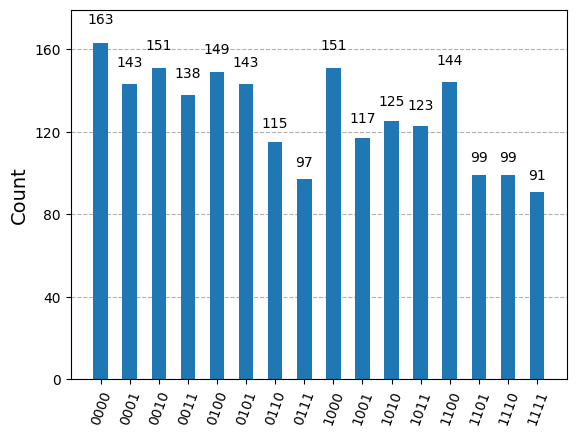

In [533]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()
sim_result = simulator.run(ising_circuit, shots=2048).result()
sim_counts = sim_result.get_counts(ising_circuit)
plot_histogram(sim_counts)

In [534]:
all_schedules = [
    [fine_q0_x1, fine_q0_sx1, q0_i1],
    [fine_q1_x2, fine_q1_sx2, q1_i2],
    [fine_q2_x1, fine_q2_sx1, q2_i1],
    [fine_q3_x2, fine_q3_sx2, q3_i2],
    # [fine_q4_x1, fine_q4_sx1, q4_i1],
    # [fine_q5_x2, fine_q5_sx2, q5_i2],
    # [fine_q6_x1, fine_q6_sx1, q6_i1],
    # [fine_q7_x2, fine_q7_sx2, q7_i2]
]

gaussian_schedules = [
    [fine_q0_x1_gaussian, fine_q0_sx1_gaussian, q0_i1],
    [fine_q1_x2_gaussian, fine_q1_sx2_gaussian, q1_i1],
    [fine_q2_x1_gaussian, fine_q2_sx1_gaussian, q2_i1],
    [fine_q3_x2_gaussian, fine_q3_sx2_gaussian, q3_i1],
]

ising_qubits = [qubit0, qubit1, qubit2, qubit3] #, qubit4, qubit5, qubit6, qubit7]

In [535]:
ising_circuit_robust = ising_circuit.copy()
ising_circuit_robust_2q = ising_circuit.copy()
ising_circuit_gaussian = ising_circuit.copy()
ising_circuit_gaussian_2q = ising_circuit.copy()
ising_circuit_default = ising_circuit.copy()

for i, qubit in enumerate(ising_qubits):
    qubit_schedules = all_schedules[i]
    gaussian_qubit_schedules = gaussian_schedules[i]

    ising_circuit_robust.add_calibration(qk.circuit.library.XGate(), (qubit,), qubit_schedules[0])
    ising_circuit_robust.add_calibration(qk.circuit.library.SXGate(), (qubit,), qubit_schedules[1])
    ising_circuit_robust.add_calibration(qk.circuit.library.IGate(), (qubit,), qubit_schedules[2])

    ising_circuit_robust_2q.add_calibration(qk.circuit.library.XGate(), (qubit,), qubit_schedules[0])
    ising_circuit_robust_2q.add_calibration(qk.circuit.library.SXGate(), (qubit,), qubit_schedules[1])
    ising_circuit_robust_2q.add_calibration(qk.circuit.library.IGate(), (qubit,), qubit_schedules[2])

    ising_circuit_gaussian.add_calibration(qk.circuit.library.XGate(), (qubit,), gaussian_qubit_schedules[0])
    ising_circuit_gaussian.add_calibration(qk.circuit.library.SXGate(), (qubit,), gaussian_qubit_schedules[1])
    ising_circuit_gaussian.add_calibration(qk.circuit.library.IGate(), (qubit,), gaussian_qubit_schedules[2])

    ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.XGate(), (qubit,), gaussian_qubit_schedules[0])
    ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.SXGate(), (qubit,), gaussian_qubit_schedules[1])
    ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.IGate(), (qubit,), gaussian_qubit_schedules[2])

ising_circuit_robust_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit2), robust_ecr_q1_q2)
ising_circuit_robust_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit0), robust_ecr_q1_q0)
ising_circuit_robust_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit3, qubit2), robust_ecr_q3_q2)

ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit2), gaussian_ecr_q1_q2)
ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit0), gaussian_ecr_q1_q0)
ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit3, qubit2), gaussian_ecr_q3_q2)

In [311]:
ising_default = sampler.run([ising_circuit_default], shots=2048)
ising_robust = sampler.run([ising_circuit_robust], shots=2048)
ising_robust_2q = sampler.run([ising_circuit_robust_2q], shots=2048)
ising_gaussian = sampler.run([ising_circuit_gaussian], shots=2048)
ising_gaussian_2q = sampler.run([ising_circuit_gaussian_2q], shots=2048)

In [538]:
ising_default.job_id(), ising_robust.job_id(), ising_robust_2q.job_id(), ising_gaussian.job_id(), ising_gaussian_2q.job_id()

('cvsg8jj4t1c0008bp470',
 'cvsg8jt9crx0008h2fz0',
 'cvsg8kag1kdg008ssye0',
 'cvsg8ktg1kdg008ssyeg',
 'cvsg8m2kv2vg008d1h5g')

In [539]:
ising_default.status(), ising_robust.status(), ising_robust_2q.status(), ising_gaussian.status(), ising_gaussian_2q.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [536]:
ising_default = service.job("cvsg8jj4t1c0008bp470")
ising_robust = service.job("cvsg8jt9crx0008h2fz0")
ising_robust_2q = service.job("cvsg8kag1kdg008ssye0")
ising_gaussian = service.job("cvsg8ktg1kdg008ssyeg")
ising_gaussian_2q = service.job("cvsg8m2kv2vg008d1h5g")

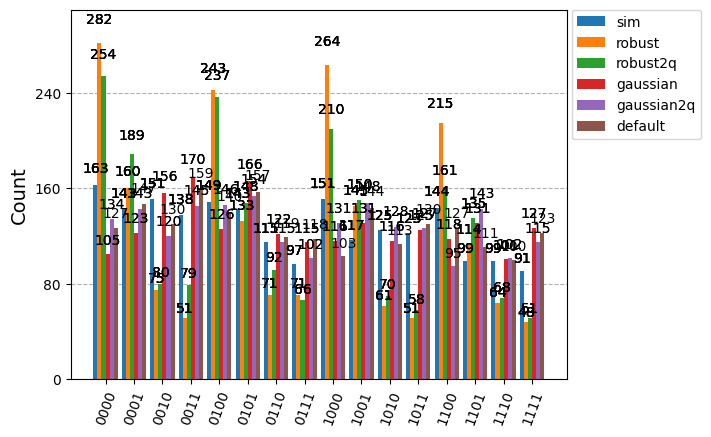

In [537]:
plot_histogram(
    [
        sim_counts, 
        ising_robust.result()[0].data.c.get_counts(),
        ising_robust_2q.result()[0].data.c.get_counts(),
        ising_gaussian.result()[0].data.c.get_counts(), 
        ising_gaussian_2q.result()[0].data.c.get_counts(), 
        ising_default.result()[0].data.c.get_counts()
    ], 
    legend = [
        "sim",
        "robust", 
        "robust2q", 
        "gaussian", 
        "gaussian2q", 
        "default"
    ]
)

In [540]:
ising_default.result()[0].data.c.expectation_values("ZZZZ"), ising_robust.result()[0].data.c.expectation_values("ZZZZ"), ising_robust_2q.result()[0].data.c.expectation_values("ZZZZ"), ising_gaussian.result()[0].data.c.expectation_values("ZZZZ"), ising_gaussian_2q.result()[0].data.c.expectation_values("ZZZZ")

(array(0.04394531),
 array(-0.01757812),
 array(-0.01855469),
 array(0.03027344),
 array(0.00976562))

In [541]:
observable = qk.quantum_info.Pauli('ZZZZ') 
ising_for_op = TransverseIsingModel(4, [0, 1, 2, 3], [])
ising_op = qk.quantum_info.Statevector(ising_for_op.second_order_Trotter_unitary(measure=False))
ising_op.expectation_value(observable)

-4.85722573273506e-17

In [542]:
print("Theoretical expectation value:", ising_op.expectation_value(observable))
print("    Default expectation value:", ising_default.result()[0].data.c.expectation_values("ZZZZ"))
print()
print("    Robust (2x length) expectation value:", ising_robust.result()[0].data.c.expectation_values("ZZZZ"))
print("    Gaussian (2x length) expectation value:", ising_gaussian.result()[0].data.c.expectation_values("ZZZZ"))
print()
print("    Robust 2q (2x length) expectation value:", ising_robust_2q.result()[0].data.c.expectation_values("ZZZZ"))
print("    Gaussian 2q (2x length) expectation value:", ising_gaussian_2q.result()[0].data.c.expectation_values("ZZZZ"))

Theoretical expectation value: -4.85722573273506e-17
    Default expectation value: 0.0439453125

    Robust (2x length) expectation value: -0.017578125
    Gaussian (2x length) expectation value: 0.0302734375

    Robust 2q (2x length) expectation value: -0.0185546875
    Gaussian 2q (2x length) expectation value: 0.009765625


In [543]:
def kl_divergence(p, q):
    dist = 0
    for k in p.keys():
        dist += p.get(k, 0) * np.log(p.get(k, 0) / q.get(k, 0))
    return dist

In [544]:
ideal_probs = ising_op.probabilities_dict()
robust_probs = {k: v / 2048 for k, v in ising_robust.result()[0].data.c.get_counts().items()}
robust_2q_probs = {k: v / 2048 for k, v in ising_robust_2q.result()[0].data.c.get_counts().items()}
gaussian_probs = {k: v / 2048 for k, v in ising_gaussian.result()[0].data.c.get_counts().items()}
gaussian_2q_probs = {k: v / 2048 for k, v in ising_gaussian_2q.result()[0].data.c.get_counts().items()}
default_probs = {k: v / 2048 for k, v in ising_default.result()[0].data.c.get_counts().items()}

In [545]:
print("Default KL divergence: ", kl_divergence(default_probs, ideal_probs))
print()
print("Robust KL divergence: ", kl_divergence(robust_probs, ideal_probs))
print("Gaussian KL divergence: ", kl_divergence(gaussian_probs, ideal_probs))
print()
print("Robust 2-qubit KL divergence: ", kl_divergence(robust_2q_probs, ideal_probs))
print("Gaussian 2-qubit KL divergence: ", kl_divergence(gaussian_2q_probs, ideal_probs))

Default KL divergence:  0.013545984630437727

Robust KL divergence:  0.12559546164276197
Gaussian KL divergence:  0.020293198799643346

Robust 2-qubit KL divergence:  0.07809535266445924
Gaussian 2-qubit KL divergence:  0.00997314602413331
